# Noise robustness: how fragile is each layer for in-context grammar learning?

**Question.** The logit lens showed *where* the grammar becomes readable (lens layer 19), and switching off heads
showed *which parts* produce it (the induction heads in blocks 18–19, `03_induction_heads`). Here we ask *how fragile*
each stage is: if we disturb the model's internal state at one layer with random noise, how much of the learning is
lost, and how much does the model's general ability suffer?

**The comparison that matters.** Noise just *before* the jump (lens layers 15–18) hits the state that the induction
heads read from: they look back at earlier words, so a noisy state should make them find the wrong word. Noise just
*after* the jump (lens layers 20+) hits a state in which the answer has already been worked out. If the learning
breaks much more easily before the jump than after it, a third, independent method confirms that the computation
happens there.

**Run order and time (Colab T4, 8-bit model).** Run all cells top to bottom. 10 layers × 5 noise strengths = 50
conditions plus the no-noise baseline, each on AGL and SRTT with 10 paired runs, plus a Wikipedia check: about
3.5 hours. Every finished condition is saved to Google Drive as it goes; after a disconnect: reconnect,
**Runtime → Run all**, approve the Drive popup, and it continues where it stopped.

In [1]:
# Stop right away if there is no GPU (NVIDIA in Colab, or an Apple Silicon Mac): on CPU the 7B model does not
# fit in memory and loading stalls.
import os
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')  # less memory fragmentation
import torch
REQUIRE_GPU = True
if torch.cuda.is_available():
  print(f"GPU: {torch.cuda.get_device_name(0)}")
elif torch.backends.mps.is_available():
  print("GPU: Apple Silicon (MPS); the model runs in float16 (8-bit loading needs an NVIDIA GPU)")
elif REQUIRE_GPU:
  raise RuntimeError("No GPU. In Colab: Runtime -> Change runtime type -> T4 GPU -> Save, then Runtime -> Run all. "
                     "If Colab says no GPU is available, its free GPU quota is used up for now: try again later.")

# Google Drive first: Colab asks for permission once per new runtime. Approve the popup right away;
# "Run all" waits here until you do. Everything slow (tuned lens, lens results) is saved there.
USE_GOOGLE_DRIVE = True
DRIVE_CACHE_DIR = '/content/drive/MyDrive/plasticity_lens_cache'
if USE_GOOGLE_DRIVE:
  try:
    from google.colab import drive
    drive.mount('/content/drive')
  except ImportError:
    print("not running in Colab; results are saved locally")

!pip install -q -U bitsandbytes
!pip install -q datasets  # tuned-lens training text


GPU: Tesla T4
Mounted at /content/drive


## Import packages

In [2]:
import json
import random
from tqdm import tqdm
random.seed(42)

## Set run parameters

In [3]:
RANDOM_WEIGHTS = False  # set to True if you want to use an untrained network
NO_REPETITIONS = False # set to False if you don't care about repetitions
model_name = 'mistral'  # paper's primary model (Mistral-7B-v0.3); use 'llama' for SI Fig. S3/S4A, 'gpt2' for SI Fig. S12
LOAD_IN_8BIT_ON_CUDA = True  # set False if your GPU has enough memory for full float16 (e.g. A100/L4); needed on a free-tier T4 (14.5GB) to avoid OOM
SEP_TOKEN = 'END'
iterations = 100
random_epochs = 85
learning_epochs = 340
END_NODE_ID = "END"
tokens_type = "words" # "words" "letters" "digits" "symbols" "all_nouns" "all_verbs"

In [4]:
def extract_subset(word_list):
    """Extracts only noun words or verbs from a list using spaCy."""
    if tokens_type == "all_nouns":
      pos = "NOUN"
    elif tokens_type == "all_verbs":
      pos = "VERB"
    print(f"extracting {pos}")
    import spacy  # only needed for tokens_type "all_nouns"/"all_verbs" (requires en_core_web_trf)
    nlp = spacy.load("en_core_web_trf")  # Load spaCy's English model
    tokens = nlp(" ".join(word_list))
    reduced = [token.text for token in nlp(" ".join(word_list)) if token.pos_ == pos]
    return reduced

In [5]:
if tokens_type == "letters":
  tokens_list = list('abcdefghijklmnopqrstuvwxyz')
elif tokens_type == "digits":
  tokens_list = list('123456789')
  SEP_TOKEN = "000"
elif tokens_type == "symbols":
  tokens_list = list('!@#$%^&*()_+-={}[]±§/\"\':;.?>,<~`´')
  SEP_TOKEN = "|"
  assert SEP_TOKEN not in tokens_list
elif tokens_type == "words" or tokens_type == "all_nouns" or tokens_type == "all_verbs":
  tokens_list = ['a', 'abandon', 'ability', 'able', 'abortion', 'about', 'above', 'abroad', 'absence', 'absolute', 'absolutely', 'absorb', 'abuse', 'academic', 'accept', 'access', 'accident', 'accompany', 'accomplish', 'according', 'account', 'accurate', 'accuse', 'achieve', 'achievement', 'acid', 'acknowledge', 'acquire', 'across', 'act', 'action', 'active', 'activist', 'activity', 'actor', 'actress', 'actual', 'actually', 'ad', 'adapt', 'add', 'addition', 'additional', 'address', 'adequate', 'adjust', 'adjustment', 'administration', 'administrator', 'admire', 'admission', 'admit', 'adolescent', 'adopt', 'adult', 'advance', 'advanced', 'advantage', 'adventure', 'advertising', 'advice', 'advise', 'adviser', 'advocate', 'affair', 'affect', 'afford', 'afraid', 'African', 'African-American', 'after', 'afternoon', 'again', 'against', 'age', 'agency', 'agenda', 'agent', 'aggressive', 'ago', 'agree', 'agreement', 'agricultural', 'ah', 'ahead', 'aid', 'aide', 'AIDS', 'aim', 'air', 'aircraft', 'airline', 'airport', 'album', 'alcohol', 'alive', 'all', 'alliance', 'allow', 'ally', 'almost', 'alone', 'along', 'already', 'also', 'alter', 'alternative', 'although', 'always', 'AM', 'amazing', 'American', 'among', 'amount', 'analysis', 'analyst', 'analyze', 'ancient', 'and', 'anger', 'angle', 'angry', 'animal', 'anniversary', 'announce', 'annual', 'another', 'answer', 'anticipate', 'anxiety', 'any', 'anybody', 'anymore', 'anyone', 'anything', 'anyway', 'anywhere', 'apart', 'apartment', 'apparent', 'apparently', 'appeal', 'appear', 'appearance', 'apple', 'application', 'apply', 'appoint', 'appointment', 'appreciate', 'approach', 'appropriate', 'approval', 'approve', 'approximately', 'Arab', 'architect', 'area', 'argue', 'argument', 'arise', 'arm', 'armed', 'army', 'around', 'arrange', 'arrangement', 'arrest', 'arrival', 'arrive', 'art', 'article', 'artist', 'artistic', 'as', 'Asian', 'aside', 'ask', 'asleep', 'aspect', 'assault', 'assert', 'assess', 'assessment', 'asset', 'assign', 'assignment', 'assist', 'assistance', 'assistant', 'associate', 'association', 'assume', 'assumption', 'assure', 'at', 'athlete', 'athletic', 'atmosphere', 'attach', 'attack', 'attempt', 'attend', 'attention', 'attitude', 'attorney', 'attract', 'attractive', 'attribute', 'audience', 'author', 'authority', 'auto', 'available', 'average', 'avoid', 'award', 'aware', 'awareness', 'away', 'awful', 'baby', 'back', 'background', 'bad', 'badly', 'bag', 'bake', 'balance', 'ball', 'ban', 'band', 'bank', 'bar', 'barely', 'barrel', 'barrier', 'base', 'baseball', 'basic', 'basically', 'basis', 'basket', 'basketball', 'bathroom', 'battery', 'battle', 'be', 'beach', 'bean', 'bear', 'beat', 'beautiful', 'beauty', 'because', 'become', 'bed', 'bedroom', 'beer', 'before', 'begin', 'beginning', 'behavior', 'behind', 'being', 'belief', 'believe', 'bell', 'belong', 'below', 'belt', 'bench', 'bend', 'beneath', 'benefit', 'beside', 'besides', 'best', 'bet', 'better', 'between', 'beyond', 'Bible', 'big', 'bike', 'bill', 'billion', 'bind', 'biological', 'bird', 'birth', 'birthday', 'bit', 'bite', 'black', 'blade', 'blame', 'blanket', 'blind', 'block', 'blood', 'blow', 'blue', 'board', 'boat', 'body', 'bomb', 'bombing', 'bond', 'bone', 'book', 'boom', 'boot', 'border', 'born', 'borrow', 'boss', 'both', 'bother', 'bottle', 'bottom', 'boundary', 'bowl', 'box', 'boy', 'boyfriend', 'brain', 'branch', 'brand', 'bread', 'break', 'breakfast', 'breast', 'breath', 'breathe', 'brick', 'bridge', 'brief', 'briefly', 'bright', 'brilliant', 'bring', 'British', 'broad', 'broken', 'brother', 'brown', 'brush', 'buck', 'budget', 'build', 'building', 'bullet', 'bunch', 'burden', 'burn', 'bury', 'bus', 'business', 'busy', 'but', 'butter', 'button', 'buy', 'buyer', 'by', 'cabin', 'cabinet', 'cable', 'cake', 'calculate', 'call', 'camera', 'camp', 'campaign', 'campus', 'can', 'Canadian', 'cancer', 'candidate', 'cap', 'capability', 'capable', 'capacity', 'capital', 'captain', 'capture', 'car', 'carbon', 'card', 'care', 'career', 'careful', 'carefully', 'carrier', 'carry', 'case', 'cash', 'cast', 'cat', 'catch', 'category', 'Catholic', 'cause', 'ceiling', 'celebrate', 'celebration', 'celebrity', 'cell', 'center', 'central', 'century', 'CEO', 'ceremony', 'certain', 'certainly', 'chain', 'chair', 'chairman', 'challenge', 'chamber', 'champion', 'championship', 'chance', 'change', 'changing', 'channel', 'chapter', 'character', 'characteristic', 'characterize', 'charge', 'charity', 'chart', 'chase', 'cheap', 'check', 'cheek', 'cheese', 'chef', 'chemical', 'chest', 'chicken', 'chief', 'child', 'childhood', 'Chinese', 'chip', 'chocolate', 'choice', 'cholesterol', 'choose', 'Christian', 'Christmas', 'church', 'cigarette', 'circle', 'circumstance', 'cite', 'citizen', 'city', 'civil', 'civilian', 'claim', 'class', 'classic', 'classroom', 'clean', 'clear', 'clearly', 'client', 'climate', 'climb', 'clinic', 'clinical', 'clock', 'close', 'closely', 'closer', 'clothes', 'clothing', 'cloud', 'club', 'clue', 'cluster', 'coach', 'coal', 'coalition', 'coast', 'coat', 'code', 'coffee', 'cognitive', 'cold', 'collapse', 'colleague', 'collect', 'collection', 'collective', 'college', 'colonial', 'color', 'column', 'combination', 'combine', 'come', 'comedy', 'comfort', 'comfortable', 'command', 'commander', 'comment', 'commercial', 'commission', 'commit', 'commitment', 'committee', 'common', 'communicate', 'communication', 'community', 'company', 'compare', 'comparison', 'compete', 'competition', 'competitive', 'competitor', 'complain', 'complaint', 'complete', 'completely', 'complex', 'complicated', 'component', 'compose', 'composition', 'comprehensive', 'computer', 'concentrate', 'concentration', 'concept', 'concern', 'concerned', 'concert', 'conclude', 'conclusion', 'concrete', 'condition', 'conduct', 'conference', 'confidence', 'confident', 'confirm', 'conflict', 'confront', 'confusion', 'Congress', 'congressional', 'connect', 'connection', 'consciousness', 'consensus', 'consequence', 'conservative', 'consider', 'considerable', 'consideration', 'consist', 'consistent', 'constant', 'constantly', 'constitute', 'constitutional', 'construct', 'construction', 'consultant', 'consume', 'consumer', 'consumption', 'contact', 'contain', 'container', 'contemporary', 'content', 'contest', 'context', 'continue', 'continued', 'contract', 'contrast', 'contribute', 'contribution', 'control', 'controversial', 'controversy', 'convention', 'conventional', 'conversation', 'convert', 'conviction', 'convince', 'cook', 'cookie', 'cooking', 'cool', 'cooperation', 'cop', 'cope', 'copy', 'core', 'corn', 'corner', 'corporate', 'corporation', 'correct', 'correspondent', 'cost', 'cotton', 'couch', 'could', 'council', 'counselor', 'count', 'counter', 'country', 'county', 'couple', 'courage', 'course', 'court', 'cousin', 'cover', 'coverage', 'cow', 'crack', 'craft', 'crash', 'crazy', 'cream', 'create', 'creation', 'creative', 'creature', 'credit', 'crew', 'crime', 'criminal', 'crisis', 'criteria', 'critic', 'critical', 'criticism', 'criticize', 'crop', 'cross', 'crowd', 'crucial', 'cry', 'cultural', 'culture', 'cup', 'curious', 'current', 'currently', 'curriculum', 'custom', 'customer', 'cut', 'cycle', 'dad', 'daily', 'damage', 'dance', 'danger', 'dangerous', 'dare', 'dark', 'darkness', 'data', 'date', 'daughter', 'day', 'dead', 'deal', 'dealer', 'dear', 'death', 'debate', 'debt', 'decade', 'decide', 'decision', 'deck', 'declare', 'decline', 'decrease', 'deep', 'deeply', 'deer', 'defeat', 'defend', 'defendant', 'defense', 'defensive', 'deficit', 'define', 'definitely', 'definition', 'degree', 'delay', 'deliver', 'delivery', 'demand', 'democracy', 'Democrat', 'democratic', 'demonstrate', 'demonstration', 'deny', 'department', 'depend', 'dependent', 'depending', 'depict', 'depression', 'depth', 'deputy', 'derive', 'describe', 'description', 'desert', 'deserve', 'design', 'designer', 'desire', 'desk', 'desperate', 'despite', 'destroy', 'destruction', 'detail', 'detailed', 'detect', 'determine', 'develop', 'developing', 'development', 'device', 'devote', 'dialogue', 'die', 'diet', 'differ', 'difference', 'different', 'differently', 'difficult', 'difficulty', 'dig', 'digital', 'dimension', 'dining', 'dinner', 'direct', 'direction', 'directly', 'director', 'dirt', 'dirty', 'disability', 'disagree', 'disappear', 'disaster', 'discipline', 'discourse', 'discover', 'discovery', 'discrimination', 'discuss', 'discussion', 'disease', 'dish', 'dismiss', 'disorder', 'display', 'dispute', 'distance', 'distant', 'distinct', 'distinction', 'distinguish', 'distribute', 'distribution', 'district', 'diverse', 'diversity', 'divide', 'division', 'divorce', 'DNA', 'do', 'doctor', 'document', 'dog', 'domestic', 'dominant', 'dominate', 'door', 'double', 'doubt', 'down', 'downtown', 'dozen', 'draft', 'drag', 'drama', 'dramatic', 'dramatically', 'draw', 'drawing', 'dream', 'dress', 'drink', 'drive', 'driver', 'drop', 'drug', 'dry', 'due', 'during', 'dust', 'duty', 'each', 'eager', 'ear', 'early', 'earn', 'earnings', 'earth', 'ease', 'easily', 'east', 'eastern', 'easy', 'eat', 'economic', 'economics', 'economist', 'economy', 'edge', 'edition', 'editor', 'educate', 'education', 'educational', 'educator', 'effect', 'effective', 'effectively', 'efficiency', 'efficient', 'effort', 'egg', 'eight', 'either', 'elderly', 'elect', 'election', 'electric', 'electricity', 'electronic', 'element', 'elementary', 'eliminate', 'elite', 'else', 'elsewhere', 'e-mail', 'embrace', 'emerge', 'emergency', 'emission', 'emotion', 'emotional', 'emphasis', 'emphasize', 'employ', 'employee', 'employer', 'employment', 'empty', 'enable', 'encounter', 'encourage', 'enemy', 'energy', 'enforcement', 'engage', 'engine', 'engineer', 'engineering', 'English', 'enhance', 'enjoy', 'enormous', 'enough', 'ensure', 'enter', 'enterprise', 'entertainment', 'entire', 'entirely', 'entrance', 'entry', 'environment', 'environmental', 'episode', 'equal', 'equally', 'equipment', 'era', 'error', 'escape', 'especially', 'essay', 'essential', 'essentially', 'establish', 'establishment', 'estate', 'estimate', 'etc', 'ethics', 'ethnic', 'European', 'evaluate', 'evaluation', 'even', 'evening', 'event', 'eventually', 'ever', 'every', 'everybody', 'everyday', 'everyone', 'everything', 'everywhere', 'evidence', 'evolution', 'evolve', 'exact', 'exactly', 'examination', 'examine', 'example', 'exceed', 'excellent', 'except', 'exception', 'exchange', 'exciting', 'executive', 'exercise', 'exhibit', 'exhibition', 'exist', 'existence', 'existing', 'expand', 'expansion', 'expect', 'expectation', 'expense', 'expensive', 'experience', 'experiment', 'expert', 'explain', 'explanation', 'explode', 'explore', 'explosion', 'expose', 'exposure', 'express', 'expression', 'extend', 'extension', 'extensive', 'extent', 'external', 'extra', 'extraordinary', 'extreme', 'extremely', 'eye', 'fabric', 'face', 'facility', 'fact', 'factor', 'factory', 'faculty', 'fade', 'fail', 'failure', 'fair', 'fairly', 'faith', 'fall', 'false', 'familiar', 'family', 'famous', 'fan', 'fantasy', 'far', 'farm', 'farmer', 'fashion', 'fast', 'fat', 'fate', 'father', 'fault', 'favor', 'favorite', 'fear', 'feature', 'federal', 'fee', 'feed', 'feel', 'feeling', 'fellow', 'female', 'fence', 'few', 'fewer', 'fiber', 'fiction', 'field', 'fifteen', 'fifth', 'fifty', 'fight', 'fighter', 'fighting', 'figure', 'file', 'fill', 'film', 'final', 'finally', 'finance', 'financial', 'find', 'finding', 'fine', 'finger', 'finish', 'fire', 'firm', 'first', 'fish', 'fishing', 'fit', 'fitness', 'five', 'fix', 'flag', 'flame', 'flat', 'flavor', 'flee', 'flesh', 'flight', 'float', 'floor', 'flow', 'flower', 'fly', 'focus', 'folk', 'follow', 'following', 'food', 'foot', 'football', 'for', 'force', 'foreign', 'forest', 'forever', 'forget', 'form', 'formal', 'formation', 'former', 'formula', 'forth', 'fortune', 'forward', 'found', 'foundation', 'founder', 'four', 'fourth', 'frame', 'framework', 'free', 'freedom', 'freeze', 'French', 'frequency', 'frequent', 'frequently', 'fresh', 'friend', 'friendly', 'friendship', 'from', 'front', 'fruit', 'frustration', 'fuel', 'full', 'fully', 'fun', 'function', 'fund', 'fundamental', 'funding', 'funeral', 'funny', 'furniture', 'furthermore', 'future', 'gain', 'galaxy', 'gallery', 'game', 'gang', 'gap', 'garage', 'garden', 'garlic', 'gas', 'gate', 'gather', 'gay', 'gaze', 'gear', 'gender', 'gene', 'general', 'generally', 'generate', 'generation', 'genetic', 'gentleman', 'gently', 'German', 'gesture', 'get', 'ghost', 'giant', 'gift', 'gifted', 'girl', 'girlfriend', 'give', 'given', 'glad', 'glance', 'glass', 'global', 'glove', 'go', 'goal', 'God', 'gold', 'golden', 'golf', 'good', 'government', 'governor', 'grab', 'grade', 'gradually', 'graduate', 'grain', 'grand', 'grandfather', 'grandmother', 'grant', 'grass', 'grave', 'gray', 'great', 'greatest', 'green', 'grocery', 'ground', 'group', 'grow', 'growing', 'growth', 'guarantee', 'guard', 'guess', 'guest', 'guide', 'guideline', 'guilty', 'gun', 'guy', 'habit', 'habitat', 'hair', 'half', 'hall', 'hand', 'handful', 'handle', 'hang', 'happen', 'happy', 'hard', 'hardly', 'hat', 'hate', 'have', 'he', 'head', 'headline', 'headquarters', 'health', 'healthy', 'hear', 'hearing', 'heart', 'heat', 'heaven', 'heavily', 'heavy', 'heel', 'height', 'helicopter', 'hell', 'hello', 'help', 'helpful', 'her', 'here', 'heritage', 'hero', 'herself', 'hey', 'hi', 'hide', 'high', 'highlight', 'highly', 'highway', 'hill', 'him', 'himself', 'hip', 'hire', 'his', 'historian', 'historic', 'historical', 'history', 'hit', 'hold', 'hole', 'holiday', 'holy', 'home', 'homeless', 'honest', 'honey', 'honor', 'hope', 'horizon', 'horror', 'horse', 'hospital', 'host', 'hot', 'hotel', 'hour', 'house', 'household', 'housing', 'how', 'however', 'huge', 'human', 'humor', 'hundred', 'hungry', 'hunter', 'hunting', 'hurt', 'husband', 'hypothesis', 'I', 'ice', 'idea', 'ideal', 'identification', 'identify', 'identity', 'ie', 'if', 'ignore', 'ill', 'illegal', 'illness', 'illustrate', 'image', 'imagination', 'imagine', 'immediate', 'immediately', 'immigrant', 'immigration', 'impact', 'implement', 'implication', 'imply', 'importance', 'important', 'impose', 'impossible', 'impress', 'impression', 'impressive', 'improve', 'improvement', 'in', 'incentive', 'incident', 'include', 'including', 'income', 'incorporate', 'increase', 'increased', 'increasing', 'increasingly', 'incredible', 'indeed', 'independence', 'independent', 'index', 'Indian', 'indicate', 'indication', 'individual', 'industrial', 'industry', 'infant', 'infection', 'inflation', 'influence', 'inform', 'information', 'ingredient', 'initial', 'initially', 'initiative', 'injury', 'inner', 'innocent', 'inquiry', 'inside', 'insight', 'insist', 'inspire', 'install', 'instance', 'instead', 'institution', 'institutional', 'instruction', 'instructor', 'instrument', 'insurance', 'intellectual', 'intelligence', 'intend', 'intense', 'intensity', 'intention', 'interaction', 'interest', 'interested', 'interesting', 'internal', 'international', 'Internet', 'interpret', 'interpretation', 'intervention', 'interview', 'into', 'introduce', 'introduction', 'invasion', 'invest', 'investigate', 'investigation', 'investigator', 'investment', 'investor', 'invite', 'involve', 'involved', 'involvement', 'Iraqi', 'Irish', 'iron', 'Islamic', 'island', 'Israeli', 'issue', 'it', 'Italian', 'item', 'its', 'itself', 'jacket', 'jail', 'Japanese', 'jet', 'Jew', 'Jewish', 'job', 'join', 'joint', 'joke', 'journal', 'journalist', 'journey', 'joy', 'judge', 'judgment', 'juice', 'jump', 'junior', 'jury', 'just', 'justice', 'justify', 'keep', 'key', 'kick', 'kid', 'kill', 'killer', 'killing', 'kind', 'king', 'kiss', 'kitchen', 'knee', 'knife', 'knock', 'know', 'knowledge', 'lab', 'label', 'labor', 'laboratory', 'lack', 'lady', 'lake', 'land', 'landscape', 'language', 'lap', 'large', 'largely', 'last', 'late', 'later', 'Latin', 'latter', 'laugh', 'launch', 'law', 'lawn', 'lawsuit', 'lawyer', 'lay', 'layer', 'lead', 'leader', 'leadership', 'leading', 'leaf', 'league', 'lean', 'learn', 'learning', 'least', 'leather', 'leave', 'left', 'leg', 'legacy', 'legal', 'legend', 'legislation', 'legitimate', 'lemon', 'length', 'less', 'lesson', 'let', 'letter', 'level', 'liberal', 'library', 'license', 'lie', 'life', 'lifestyle', 'lifetime', 'lift', 'light', 'like', 'likely', 'limit', 'limitation', 'limited', 'line', 'link', 'lip', 'list', 'listen', 'literally', 'literary', 'literature', 'little', 'live', 'living', 'load', 'loan', 'local', 'locate', 'location', 'lock', 'long', 'long-term', 'look', 'loose', 'lose', 'loss', 'lost', 'lot', 'lots', 'loud', 'love', 'lovely', 'lover', 'low', 'lower', 'luck', 'lucky', 'lunch', 'lung', 'machine', 'mad', 'magazine', 'mail', 'main', 'mainly', 'maintain', 'maintenance', 'major', 'majority', 'make', 'maker', 'makeup', 'male', 'mall', 'man', 'manage', 'management', 'manager', 'manner', 'manufacturer', 'manufacturing', 'many', 'map', 'margin', 'mark', 'market', 'marketing', 'marriage', 'married', 'marry', 'mask', 'mass', 'massive', 'master', 'match', 'material', 'math', 'matter', 'may', 'maybe', 'mayor', 'me', 'meal', 'mean', 'meaning', 'meanwhile', 'measure', 'measurement', 'meat', 'mechanism', 'media', 'medical', 'medication', 'medicine', 'medium', 'meet', 'meeting', 'member', 'membership', 'memory', 'mental', 'mention', 'menu', 'mere', 'merely', 'mess', 'message', 'metal', 'meter', 'method', 'Mexican', 'middle', 'might', 'military', 'milk', 'million', 'mind', 'mine', 'minister', 'minor', 'minority', 'minute', 'miracle', 'mirror', 'miss', 'missile', 'mission', 'mistake', 'mix', 'mixture', 'mm-hmm', 'mode', 'model', 'moderate', 'modern', 'modest', 'mom', 'moment', 'money', 'monitor', 'month', 'mood', 'moon', 'moral', 'more', 'moreover', 'morning', 'mortgage', 'most', 'mostly', 'mother', 'motion', 'motivation', 'motor', 'mount', 'mountain', 'mouse', 'mouth', 'move', 'movement', 'movie', 'Mr', 'Mrs', 'Ms', 'much', 'multiple', 'murder', 'muscle', 'museum', 'music', 'musical', 'musician', 'Muslim', 'must', 'mutual', 'my', 'myself', 'mystery', 'myth', 'naked', 'name', 'narrative', 'narrow', 'nation', 'national', 'native', 'natural', 'naturally', 'nature', 'near', 'nearby', 'nearly', 'necessarily', 'necessary', 'neck', 'need', 'negative', 'negotiate', 'negotiation', 'neighbor', 'neighborhood', 'neither', 'nerve', 'nervous', 'net', 'network', 'never', 'nevertheless', 'new', 'newly', 'news', 'newspaper', 'next', 'nice', 'night', 'nine', 'no', 'nobody', 'nod', 'noise', 'nomination', 'none', 'nonetheless', 'nor', 'normal', 'normally', 'north', 'northern', 'nose', 'not', 'note', 'nothing', 'notice', 'notion', 'novel', 'now', 'nowhere', "n't", 'nuclear', 'number', 'nurse', 'nut', 'object', 'objective', 'obligation', 'observation', 'observe', 'observer', 'obtain', 'obvious', 'obviously', 'occasion', 'occasionally', 'occupation', 'occupy', 'occur', 'ocean', 'odd', 'odds', 'of', 'off', 'offense', 'offensive', 'offer', 'office', 'officer', 'official', 'often', 'oh', 'oil', 'ok', 'okay', 'old', 'Olympic', 'on', 'once', 'one', 'ongoing', 'onion', 'online', 'only', 'onto', 'open', 'opening', 'operate', 'operating', 'operation', 'operator', 'opinion', 'opponent', 'opportunity', 'oppose', 'opposite', 'opposition', 'option', 'or', 'orange', 'order', 'ordinary', 'organic', 'organization', 'organize', 'orientation', 'origin', 'original', 'originally', 'other', 'others', 'otherwise', 'ought', 'our', 'ourselves', 'out', 'outcome', 'outside', 'oven', 'over', 'overall', 'overcome', 'overlook', 'owe', 'own', 'owner', 'pace', 'pack', 'package', 'page', 'pain', 'painful', 'paint', 'painter', 'painting', 'pair', 'pale', 'Palestinian', 'palm', 'pan', 'panel', 'pant', 'paper', 'parent', 'park', 'parking', 'part', 'participant', 'participate', 'participation', 'particular', 'particularly', 'partly', 'partner', 'partnership', 'party', 'pass', 'passage', 'passenger', 'passion', 'past', 'patch', 'path', 'patient', 'pattern', 'pause', 'pay', 'payment', 'PC', 'peace', 'peak', 'peer', 'penalty', 'people', 'pepper', 'per', 'perceive', 'percentage', 'perception', 'perfect', 'perfectly', 'perform', 'performance', 'perhaps', 'period', 'permanent', 'permission', 'permit', 'person', 'personal', 'personality', 'personally', 'personnel', 'perspective', 'persuade', 'pet', 'phase', 'phenomenon', 'philosophy', 'phone', 'photo', 'photograph', 'photographer', 'phrase', 'physical', 'physically', 'physician', 'piano', 'pick', 'picture', 'pie', 'piece', 'pile', 'pilot', 'pine', 'pink', 'pipe', 'pitch', 'place', 'plan', 'plane', 'planet', 'planning', 'plant', 'plastic', 'plate', 'platform', 'play', 'player', 'please', 'pleasure', 'plenty', 'plot', 'plus', 'PM', 'pocket', 'poem', 'poet', 'poetry', 'point', 'pole', 'police', 'policy', 'political', 'politically', 'politician', 'politics', 'poll', 'pollution', 'pool', 'poor', 'pop', 'popular', 'population', 'porch', 'port', 'portion', 'portrait', 'portray', 'pose', 'position', 'positive', 'possess', 'possibility', 'possible', 'possibly', 'post', 'pot', 'potato', 'potential', 'potentially', 'pound', 'pour', 'poverty', 'powder', 'power', 'powerful', 'practical', 'practice', 'pray', 'prayer', 'precisely', 'predict', 'prefer', 'preference', 'pregnancy', 'pregnant', 'preparation', 'prepare', 'prescription', 'presence', 'present', 'presentation', 'preserve', 'president', 'presidential', 'press', 'pressure', 'pretend', 'pretty', 'prevent', 'previous', 'previously', 'price', 'pride', 'priest', 'primarily', 'primary', 'prime', 'principal', 'principle', 'print', 'prior', 'priority', 'prison', 'prisoner', 'privacy', 'private', 'probably', 'problem', 'procedure', 'proceed', 'process', 'produce', 'producer', 'product', 'production', 'profession', 'professional', 'professor', 'profile', 'profit', 'program', 'progress', 'project', 'prominent', 'promise', 'promote', 'prompt', 'proof', 'proper', 'properly', 'property', 'proportion', 'proposal', 'propose', 'proposed', 'prosecutor', 'prospect', 'protect', 'protection', 'protein', 'protest', 'proud', 'prove', 'provide', 'provider', 'province', 'provision', 'psychological', 'psychologist', 'psychology', 'public', 'publication', 'publicly', 'publish', 'publisher', 'pull', 'punishment', 'purchase', 'pure', 'purpose', 'pursue', 'push', 'put', 'qualify', 'quality', 'quarter', 'quarterback', 'question', 'quick', 'quickly', 'quiet', 'quietly', 'quit', 'quite', 'quote', 'race', 'racial', 'radical', 'radio', 'rail', 'rain', 'raise', 'range', 'rank', 'rapid', 'rapidly', 'rare', 'rarely', 'rate', 'rather', 'rating', 'ratio', 'raw', 'reach', 'react', 'reaction', 'read', 'reader', 'reading', 'ready', 'real', 'reality', 'realize', 'really', 'reason', 'reasonable', 'recall', 'receive', 'recent', 'recently', 'recipe', 'recognition', 'recognize', 'recommend', 'recommendation', 'record', 'recording', 'recover', 'recovery', 'recruit', 'red', 'reduce', 'reduction', 'refer', 'reference', 'reflect', 'reflection', 'reform', 'refugee', 'refuse', 'regard', 'regarding', 'regardless', 'regime', 'region', 'regional', 'register', 'regular', 'regularly', 'regulate', 'regulation', 'reinforce', 'reject', 'relate', 'relation', 'relationship', 'relative', 'relatively', 'relax', 'release', 'relevant', 'relief', 'religion', 'religious', 'rely', 'remain', 'remaining', 'remarkable', 'remember', 'remind', 'remote', 'remove', 'repeat', 'repeatedly', 'replace', 'reply', 'report', 'reporter', 'represent', 'representation', 'representative', 'Republican', 'reputation', 'request', 'require', 'requirement', 'research', 'researcher', 'resemble', 'reservation', 'resident', 'resist', 'resistance', 'resolution', 'resolve', 'resort', 'resource', 'respect', 'respond', 'respondent', 'response', 'responsibility', 'responsible', 'rest', 'restaurant', 'restore', 'restriction', 'result', 'retain', 'retire', 'retirement', 'return', 'reveal', 'revenue', 'review', 'revolution', 'rhythm', 'rice', 'rich', 'rid', 'ride', 'rifle', 'right', 'ring', 'rise', 'risk', 'river', 'road', 'rock', 'role', 'roll', 'romantic', 'roof', 'room', 'root', 'rope', 'rose', 'rough', 'roughly', 'round', 'route', 'routine', 'row', 'rub', 'rule', 'run', 'running', 'rural', 'rush', 'Russian', 'sacred', 'sad', 'safe', 'safety', 'sake', 'salad', 'salary', 'sale', 'sales', 'salt', 'same', 'sample', 'sanction', 'sand', 'satellite', 'satisfaction', 'satisfy', 'sauce', 'save', 'saving', 'say', 'scale', 'scandal', 'scared', 'scenario', 'scene', 'schedule', 'scheme', 'scholar', 'scholarship', 'school', 'science', 'scientific', 'scientist', 'scope', 'score', 'scream', 'screen', 'script', 'sea', 'search', 'season', 'seat', 'second', 'secret', 'secretary', 'section', 'sector', 'secure', 'security', 'see', 'seed', 'seek', 'seem', 'segment', 'seize', 'select', 'selection', 'self', 'sell', 'Senate', 'senator', 'send', 'senior', 'sense', 'sensitive', 'sentence', 'separate', 'sequence', 'series', 'serious', 'seriously', 'serve', 'service', 'session', 'set', 'setting', 'settle', 'settlement', 'seven', 'several', 'severe', 'sex', 'sexual', 'shade', 'shadow', 'shake', 'shall', 'shape', 'share', 'sharp', 'she', 'sheet', 'shelf', 'shell', 'shelter', 'shift', 'shine', 'ship', 'shirt', 'shit', 'shock', 'shoe', 'shoot', 'shooting', 'shop', 'shopping', 'shore', 'short', 'shortly', 'shot', 'should', 'shoulder', 'shout', 'show', 'shower', 'shrug', 'shut', 'sick', 'side', 'sigh', 'sight', 'sign', 'signal', 'significance', 'significant', 'significantly', 'silence', 'silent', 'silver', 'similar', 'similarly', 'simple', 'simply', 'sin', 'since', 'sing', 'singer', 'single', 'sink', 'sir', 'sister', 'sit', 'site', 'situation', 'six', 'size', 'ski', 'skill', 'skin', 'sky', 'slave', 'sleep', 'slice', 'slide', 'slight', 'slightly', 'slip', 'slow', 'slowly', 'small', 'smart', 'smell', 'smile', 'smoke', 'smooth', 'snap', 'snow', 'so', 'so-called', 'soccer', 'social', 'society', 'soft', 'software', 'soil', 'solar', 'soldier', 'solid', 'solution', 'solve', 'some', 'somebody', 'somehow', 'someone', 'something', 'sometimes', 'somewhat', 'somewhere', 'son', 'song', 'soon', 'sophisticated', 'sorry', 'sort', 'soul', 'sound', 'soup', 'source', 'south', 'southern', 'Soviet', 'space', 'Spanish', 'speak', 'speaker', 'special', 'specialist', 'species', 'specific', 'specifically', 'speech', 'speed', 'spend', 'spending', 'spin', 'spirit', 'spiritual', 'split', 'spokesman', 'sport', 'spot', 'spread', 'spring', 'square', 'squeeze', 'stability', 'stable', 'staff', 'stage', 'stair', 'stake', 'stand', 'standard', 'standing', 'star', 'stare', 'start', 'state', 'statement', 'station', 'statistics', 'status', 'stay', 'steady', 'steal', 'steel', 'step', 'stick', 'still', 'stir', 'stock', 'stomach', 'stone', 'stop', 'storage', 'store', 'storm', 'story', 'straight', 'strange', 'stranger', 'strategic', 'strategy', 'stream', 'street', 'strength', 'strengthen', 'stress', 'stretch', 'strike', 'string', 'strip', 'stroke', 'strong', 'strongly', 'structure', 'struggle', 'student', 'studio', 'study', 'stuff', 'stupid', 'style', 'subject', 'submit', 'subsequent', 'substance', 'substantial', 'succeed', 'success', 'successful', 'successfully', 'such', 'sudden', 'suddenly', 'sue', 'suffer', 'sufficient', 'sugar', 'suggest', 'suggestion', 'suicide', 'suit', 'summer', 'summit', 'sun', 'super', 'supply', 'support', 'supporter', 'suppose', 'supposed', 'Supreme', 'sure', 'surely', 'surface', 'surgery', 'surprise', 'surprised', 'surprising', 'surprisingly', 'surround', 'survey', 'survival', 'survive', 'survivor', 'suspect', 'sustain', 'swear', 'sweep', 'sweet', 'swim', 'swing', 'switch', 'symbol', 'symptom', 'system', 'table', 'tablespoon', 'tactic', 'tail', 'take', 'tale', 'talent', 'talk', 'tall', 'tank', 'tap', 'tape', 'target', 'task', 'taste', 'tax', 'taxpayer', 'tea', 'teach', 'teacher', 'teaching', 'team', 'tear', 'teaspoon', 'technical', 'technique', 'technology', 'teen', 'teenager', 'telephone', 'telescope', 'television', 'tell', 'temperature', 'temporary', 'ten', 'tend', 'tendency', 'tennis', 'tension', 'tent', 'term', 'terms', 'terrible', 'territory', 'terror', 'terrorism', 'terrorist', 'test', 'testify', 'testimony', 'testing', 'text', 'than', 'thank', 'thanks', 'that', 'the', 'theater', 'their', 'them', 'theme', 'themselves', 'then', 'theory', 'therapy', 'there', 'therefore', 'these', 'they', 'thick', 'thin', 'thing', 'think', 'thinking', 'third', 'thirty', 'this', 'those', 'though', 'thought', 'thousand', 'threat', 'threaten', 'three', 'throat', 'through', 'throughout', 'throw', 'thus', 'ticket', 'tie', 'tight', 'time', 'tiny', 'tip', 'tire', 'tired', 'tissue', 'title', 'to', 'tobacco', 'today', 'toe', 'together', 'tomato', 'tomorrow', 'tone', 'tongue', 'tonight', 'too', 'tool', 'tooth', 'top', 'topic', 'toss', 'total', 'totally', 'touch', 'tough', 'tour', 'tourist', 'tournament', 'toward', 'towards', 'tower', 'town', 'toy', 'trace', 'track', 'trade', 'tradition', 'traditional', 'traffic', 'tragedy', 'trail', 'train', 'training', 'transfer', 'transform', 'transformation', 'transition', 'translate', 'transportation', 'travel', 'treat', 'treatment', 'treaty', 'tree', 'tremendous', 'trend', 'trial', 'tribe', 'trick', 'trip', 'troop', 'trouble', 'truck', 'true', 'truly', 'trust', 'truth', 'try', 'tube', 'tunnel', 'turn', 'TV', 'twelve', 'twenty', 'twice', 'twin', 'two', 'type', 'typical', 'typically', 'ugly', 'ultimate', 'ultimately', 'unable', 'uncle', 'under', 'undergo', 'understand', 'understanding', 'unfortunately', 'uniform', 'union', 'unique', 'unit', 'United', 'universal', 'universe', 'university', 'unknown', 'unless', 'unlike', 'unlikely', 'until', 'unusual', 'up', 'upon', 'upper', 'urban', 'urge', 'us', 'use', 'used', 'useful', 'user', 'usual', 'usually', 'utility', 'vacation', 'valley', 'valuable', 'value', 'variable', 'variation', 'variety', 'various', 'vary', 'vast', 'vegetable', 'vehicle', 'venture', 'version', 'versus', 'very', 'vessel', 'veteran', 'via', 'victim', 'victory', 'video', 'view', 'viewer', 'village', 'violate', 'violation', 'violence', 'violent', 'virtually', 'virtue', 'virus', 'visible', 'vision', 'visit', 'visitor', 'visual', 'vital', 'voice', 'volume', 'volunteer', 'vote', 'voter', 'vs', 'vulnerable', 'wage', 'wait', 'wake', 'walk', 'wall', 'wander', 'want', 'war', 'warm', 'warn', 'warning', 'wash', 'waste', 'watch', 'water', 'wave', 'way', 'we', 'weak', 'wealth', 'wealthy', 'weapon', 'wear', 'weather', 'wedding', 'week', 'weekend', 'weekly', 'weigh', 'weight', 'welcome', 'welfare', 'well', 'west', 'western', 'wet', 'what', 'whatever', 'wheel', 'when', 'whenever', 'where', 'whereas', 'whether', 'which', 'while', 'whisper', 'white', 'who', 'whole', 'whom', 'whose', 'why', 'wide', 'widely', 'widespread', 'wife', 'wild', 'will', 'willing', 'win', 'wind', 'window', 'wine', 'wing', 'winner', 'winter', 'wipe', 'wire', 'wisdom', 'wise', 'wish', 'with', 'withdraw', 'within', 'without', 'witness', 'woman', 'wonder', 'wonderful', 'wood', 'wooden', 'word', 'work', 'worker', 'working', 'works', 'workshop', 'world', 'worried', 'worry', 'worth', 'would', 'wound', 'wrap', 'write', 'writer', 'writing', 'wrong', 'yard', 'yeah', 'year', 'yell', 'yellow', 'yes', 'yesterday', 'yet', 'yield', 'you', 'young', 'your', 'yours', 'yourself', 'youth', 'zone']
  if tokens_type != "words":
    tokens_list = extract_subset(tokens_list)
else:
  print("INVALID TOKENS TYPE!!!")
print(tokens_list)

['a', 'abandon', 'ability', 'able', 'abortion', 'about', 'above', 'abroad', 'absence', 'absolute', 'absolutely', 'absorb', 'abuse', 'academic', 'accept', 'access', 'accident', 'accompany', 'accomplish', 'according', 'account', 'accurate', 'accuse', 'achieve', 'achievement', 'acid', 'acknowledge', 'acquire', 'across', 'act', 'action', 'active', 'activist', 'activity', 'actor', 'actress', 'actual', 'actually', 'ad', 'adapt', 'add', 'addition', 'additional', 'address', 'adequate', 'adjust', 'adjustment', 'administration', 'administrator', 'admire', 'admission', 'admit', 'adolescent', 'adopt', 'adult', 'advance', 'advanced', 'advantage', 'adventure', 'advertising', 'advice', 'advise', 'adviser', 'advocate', 'affair', 'affect', 'afford', 'afraid', 'African', 'African-American', 'after', 'afternoon', 'again', 'against', 'age', 'agency', 'agenda', 'agent', 'aggressive', 'ago', 'agree', 'agreement', 'agricultural', 'ah', 'ahead', 'aid', 'aide', 'AIDS', 'aim', 'air', 'aircraft', 'airline', 'air

In [6]:
agl_transitions = {
  "q0":
  {
    "0": "q0",
    "1": "q1"
  },
  "q1":
  {
    "3": "q2",
    "0": "q3",
    "2": "q4"
  },
  "q2":
  {
    SEP_TOKEN: "q0",
    "2": "q0"
  },
  "q3":
  {
    SEP_TOKEN: "q0",
    "3": "q0"
  },
  "q4":
  {
    SEP_TOKEN: "q0",
    "1": "q0"
  }
}

## Generate Sequences

In [7]:
class Transition:
    def __init__(self, word, next_node):
        self.word = word
        self.next_node = next_node

    def __repr__(self):
        return str((self.word, self.next_node))


class Node:
    def __init__(self, id_node):
        self.id = id_node
        self.transitions = []

    def __repr__(self):
        return self.id

In [8]:
def build_DFA(transitions, vocab=None):
  nodes = {}
  if vocab is not None:
      mapping_vocab = {f"{i}": word for i,word in enumerate(vocab)}
  for node in transitions:
      node_id = node
      nodes[node_id] = Node(node_id)
  nodes["END"] = Node(END_NODE_ID)
  for node in transitions:
      node_id = node
      for word in transitions[node_id]:
          next_node_id = transitions[node_id][word]
          if vocab is not None:
              word = mapping_vocab[word] if word != SEP_TOKEN else SEP_TOKEN
          transition = Transition(word, nodes[next_node_id])
          nodes[node_id].transitions.append(transition)
  return nodes["q0"]

In [9]:
def build_random_DFA(vocab):
  vocab_copy = vocab.copy()
  if SEP_TOKEN in vocab_copy:
      vocab_copy.remove(SEP_TOKEN)
  nodes = {word: Node(word) for word in vocab_copy}
  nodes['start'] = Node(END_NODE_ID)
  for node in nodes:
      transitions = [Transition(word, nodes[word]) for word in vocab_copy]
      if node != 'start':
          transitions.append(Transition(SEP_TOKEN, nodes['start']))
      nodes[node].transitions = transitions
  return nodes['start']

In [10]:
def generate_sequences_from_dfa(start_node, num_sequences_to_generate):
  node = start_node
  str_sequence = []
  state_sequence = []
  transition_probs = []
  count_sep = 0
  all_sequences = []
  current_sequence = []
  while count_sep < num_sequences_to_generate:
      transition = random.choice(node.transitions)
      if transition.word != SEP_TOKEN:
        current_sequence.append(transition.word)
      else:  # transition.word == SEP_TOKEN:
        if NO_REPETITIONS and current_sequence in all_sequences:
          str_sequence = str_sequence[:-len(current_sequence)]
          state_sequence = state_sequence[:-len(current_sequence)]
          transition_probs = transition_probs[:-len(current_sequence)]
          assert str_sequence[-1] == SEP_TOKEN
          current_sequence = []
          node = transition.next_node
          assert node == start_node
          continue
        all_sequences.append(current_sequence)
        current_sequence = []
        count_sep += 1
      str_sequence.append(transition.word)
      state_sequence.append(node.id)
      transition_probs.append({tr.word: 1 / len(node.transitions) for tr in node.transitions})
      node = transition.next_node
  final_dict = {"str_sequence": str_sequence, "state_sequence": state_sequence, "transition_probs": transition_probs}
  if NO_REPETITIONS:
    all_seqs = " ".join(str_sequence).split(SEP_TOKEN)
    all_uniques = set(all_seqs)
    assert len(all_seqs) == len(all_uniques)
  return final_dict

In [11]:
def generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node):

  learning_sequences_dict = generate_sequences_from_dfa(start_node, learning_epochs)
  placeholder_learning_prompt = learning_sequences_dict['str_sequence']
  learning_state_sequences = learning_sequences_dict['state_sequence']
  learning_transition_probabilities = learning_sequences_dict['transition_probs']

  random_dfa_start_node = build_random_DFA(set(placeholder_learning_prompt))
  random_prefix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)
  random_suffix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)

  full_prompt_placeholders = random_prefix_dict['str_sequence'] + placeholder_learning_prompt + random_suffix_dict['str_sequence']
  full_prompt_probs = random_prefix_dict['transition_probs'] + learning_transition_probabilities + random_suffix_dict['transition_probs']


  # assert len(full_prompt_placeholders) < 4096
  out_dict = {"placeholder_prompt": full_prompt_placeholders, "structure_state_sequences": learning_state_sequences,
              "transition_probabilities": full_prompt_probs, "learning_begins": len(random_prefix_dict['str_sequence']),
              "learning_ends": len(full_prompt_placeholders)-len(random_suffix_dict['str_sequence']),
              "random_epochs": random_epochs, "learning_epochs": learning_epochs}

  return out_dict

In [12]:
def map_prompt(prompt, vocab):
  assert len(vocab) == len(set(prompt))-1, "vocab length missmatch"
  mapped_prompt = [vocab[int(i)] if i != SEP_TOKEN else SEP_TOKEN for i in prompt]
  return mapped_prompt

### AGL word streams

In [13]:
dfa_start_node = build_DFA(agl_transitions)
all_placeholder_prompts = []
for i in tqdm(range(iterations)):
  full_prompt_dict = generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node=dfa_start_node)
  all_placeholder_prompts.append(full_prompt_dict)

100%|██████████| 100/100 [00:00<00:00, 141.93it/s]


In [14]:
vocab_length = len(set(all_placeholder_prompts[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts))]  # same as meeting 1

output = {"shuffle": []}
for i, prompt_dict in enumerate(all_placeholder_prompts):
  output["shuffle"].append(prompt_dict.copy())
  output["shuffle"][-1]["mapped_prompt"] = map_prompt(prompt_dict["placeholder_prompt"], shuffle_vocab[i])
  output["shuffle"][-1]["vocab"] = shuffle_vocab[i]


### SRTT word streams

In [15]:
srtt_transitions = {
    "q0":
  {
    "0": "q1"
  },
  "q1":
  {
    "1": "q2"
  },
  "q2":
  {
    "2": "q3"
  },
  "q3":
  {
    "2": "q4"
  },
  "q4":
  {
    "0": "q5"
  },
  "q5":
  {
    "2": "q6"
  },
  "q6":
  {
    "3": "q7"
  },
  "q7":
  {
    "1": "q8"
  },
  "q8":
  {
    SEP_TOKEN: "q0"
  }
}

In [16]:
srtt_random_epochs = 80
srtt_learning_epochs = 320

In [17]:
# NOTE: all SRTT runs share ONE generated sequence (including the random baseline/post segments);
# only the vocabulary differs between runs, so averaging over runs averages over vocabularies,
# not over random sequences. (The SRTT cells below also assume equal-length runs.)
srtt_dfa_start_node = build_DFA(srtt_transitions)
full_prompt_dict = generate_full_prompt_placeholders(srtt_random_epochs, srtt_learning_epochs, start_node=srtt_dfa_start_node)
all_placeholder_prompts_srtt = [full_prompt_dict.copy() for _ in range(iterations)]


In [18]:
vocab_length = len(set(all_placeholder_prompts_srtt[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts_srtt))]
for i in range(len(all_placeholder_prompts_srtt)):
  shuffle_vocab_words = shuffle_vocab[i]

output_srtt = []
for i, prompt_dict in enumerate(all_placeholder_prompts_srtt):
  output_srtt.append(prompt_dict.copy())
  vocab = shuffle_vocab[i]
  mapped_prompt = map_prompt(prompt_dict["placeholder_prompt"], vocab)
  output_srtt[-1]["mapped_prompt"] = mapped_prompt
  output_srtt[-1]["vocab"] = vocab

## Load the model

In [19]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from huggingface_hub import login
from itertools import product
from transformers import AutoConfig

In [20]:
def get_device():
  """Returns the best available torch device: cuda > mps (Apple Silicon GPU) > cpu."""
  if torch.cuda.is_available():
    return 'cuda'
  if torch.backends.mps.is_available():
    return 'mps'
  return 'cpu'


In [21]:
import logging
logging.getLogger("bitsandbytes").setLevel(logging.ERROR)  # silences repeated per-matmul cast-precision
                                                              # logging noise from the 8-bit quantized model;
                                                              # purely cosmetic, no effect on results

In [22]:
def get_model(model_name, random=False):
  """
  loads a model according to input.
  If running on device cuda, will load larger version of the model.
  :param model_name: the name of the model to load.
  :return: (tokenizer, model) according to input params.
  """
  device = get_device()
  # detects CUDA, then Apple Silicon GPU (MPS), then falls back to CPU
  print(f"device: {device}")
  print(f"loading {model_name}...")
  if model_name == 'mistral':
    model_name = f"mistralai/Mistral-7B-v0.3"
  elif model_name == 'llama':
    model_name = "meta-llama/Llama-3.1-8B"
  elif model_name == 'gemma':
    model_name = "google/gemma-2-9b"
  elif model_name == 'gpt2':
    model_name = "openai-community/gpt2-xl"
  else:
    raise RuntimeError("unsupported model")

  tokenizer = AutoTokenizer.from_pretrained(model_name, add_prefix_space=True) # add_prefix_space=True only for gpt2
  if device == 'cuda' and LOAD_IN_8BIT_ON_CUDA:
    from transformers import BitsAndBytesConfig
    quantization_config = BitsAndBytesConfig(load_in_8bit=True)
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, quantization_config=quantization_config, low_cpu_mem_usage=True)
  else:
    dtype = torch.float16 if device in ('cuda', 'mps') else torch.float32
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, dtype=dtype, low_cpu_mem_usage=True)

  # Extract relevant details
  context_length = getattr(model.config, "max_position_embeddings", tokenizer.model_max_length)
  huggingface_url = f"https://huggingface.co/{model_name}"
  num_parameters = sum(p.numel() for p in model.parameters())

  print("LOADING DONE!")

  # Print model details
  print(f"Model: {model_name}")
  print(f"Context window length: {context_length}")
  print(f"Number of parameters: {num_parameters:,}")
  print(f"Hugging Face URL: {huggingface_url}")

    # Reset all weights randomly
  def initialize_weights(module):
    if hasattr(module, 'weight') and module.weight is not None:
      torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    if hasattr(module, 'bias') and module.bias is not None:
      torch.nn.init.zeros_(module.bias)

  if random:
    print("randomizing weights")
    model.apply(initialize_weights)

  return tokenizer, model

In [24]:
def get_hf_token():
  """Reads the HF token from Colab secrets, a previously cached local login, the
  HF_TOKEN env var, or prompts for it. huggingface_hub.login() persists a valid
  token to ~/.cache/huggingface/token, so after the first successful login this
  will find it automatically and never prompt again.
  """
  try:
    from google.colab import userdata
    token = userdata.get('HF_TOKEN')
    if token:
      return token
  except ImportError:
    pass
  from huggingface_hub import get_token
  token = get_token()  # checks HF_TOKEN env var, then the cached local login
  if token:
    return token
  from getpass import getpass
  return getpass('Enter your Hugging Face token (HF_TOKEN): ')

login(token=get_hf_token())
tokenizer, model = get_model(model_name, random=RANDOM_WEIGHTS)


device: cuda
loading mistral...


config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/137k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  587kB            

tokenizer.model: downloading bytes:           |  0.00B            

... (3 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

LOADING DONE!
Model: mistralai/Mistral-7B-v0.3
Context window length: 32768
Number of parameters: 7,248,023,552
Hugging Face URL: https://huggingface.co/mistralai/Mistral-7B-v0.3


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'axes.labelsize': 14, 'xtick.labelsize': 14, 'ytick.labelsize': 14})


## Shared tools from the lens notebooks

Copied unchanged from `02_tuned_lens`: settings and Google Drive caching, the per-run extraction with saving and
resuming (`run_lens_extraction`), the learning score (`lens_phase_summary`), plotting helpers, and the Wikipedia text
loader (`load_lens_training_tokens`). Only the model's final output is used here.

In [26]:
import os

LAYERS_TO_DECODE = 'all'  # 'all' decodes every layer (0 = embedding output, 1..32 = after each transformer block);
                          # or set a list like [0, 8, 16, 24, 32] for a lighter run
LENS_CACHE_DIR = 'lens_cache'  # per-condition results are pickled here and reloaded if the inputs match;
                               # point it at a mounted Google Drive folder to survive a Colab reconnect. None = off
LAST_N_STRUCTURED = 1000  # summary window: last (and first) N tokens of the structured phase
BASELINE_WARMUP = 50  # skip the first N baseline tokens (the model has not seen the alphabet yet; full-vocab P climbs from ~0)

# Tuned lens (trained once on generic text, never on the grammar task; see "Tuned lens" below)
TUNED_LENS_DATASET = ("Salesforce/wikitext", "wikitext-103-raw-v1")  # (HF dataset, config), streamed
TUNED_LENS_STEPS = 400        # optimizer steps (~40 min on a T4)
TUNED_LENS_BATCH = 2          # sequences per step (2 x 512 fits a 15 GB T4 next to the 8-bit model)
TUNED_LENS_SEQ_LEN = 512      # tokens per sequence (BOS + 511)
TUNED_LENS_POSITIONS_PER_SEQ = 128  # train on a random subset of positions per sequence: the lens (not the model)
                                    # is most of the cost per position, and neighbouring positions are redundant
TUNED_LENS_LR = 1.0           # SGD with Nesterov momentum, linear decay to 0 (as in Belrose et al. 2023)
TUNED_LENS_MOMENTUM = 0.9
TUNED_LENS_WEIGHT_DECAY = 1e-3
TUNED_LENS_VAL_SEQS = 16      # held-out sequences (validation split) for the lens-quality check
TUNED_LENS_CHECKPOINT_EVERY = 50  # save training progress every N steps (~5 min on a T4) and resume from it
LENS_RUNS_PER_SAVE = 10  # lens passes save their progress every N runs and resume from there

if USE_GOOGLE_DRIVE and os.path.isdir('/content/drive/MyDrive'):
  LENS_CACHE_DIR = DRIVE_CACHE_DIR
print(f"saving the tuned lens and lens results to: {LENS_CACHE_DIR}")


def lens_cache_name(grammar):
  """Cache key includes everything that changes the numbers for the same input tokens."""
  quant = '8bit' if (get_device() == 'cuda' and LOAD_IN_8BIT_ON_CUDA) else ('fp16' if get_device() in ('cuda', 'mps') else 'fp32')
  return f"{grammar}_{model_name}_{'rand' if RANDOM_WEIGHTS else 'trained'}_{quant}"


saving the tuned lens and lens results to: /content/drive/MyDrive/plasticity_lens_cache


In [27]:
def get_layer_logits(model, hidden_state, is_last):
  """Logit lens: applies the model's own final norm + LM head to one layer's hidden state.
  hidden_states[-1] has already been through model.model.norm in HF Mistral/Llama, so the
  last layer goes straight to lm_head (norming it twice changes its direction). Returns float32."""
  if model_name not in ('mistral', 'llama'):
    raise NotImplementedError(
      f"get_layer_logits only supports mistral/llama-style architectures (model.model.norm + "
      f"model.lm_head), got model_name={model_name!r}"
    )
  with torch.no_grad():
    h = hidden_state if is_last else model.model.norm(hidden_state)
    return model.lm_head(h).float()


class TunedLens(torch.nn.Module):
  """One affine "translator" per layer (Belrose et al. 2023): h -> h + W h + b, initialized to zero
  (i.e. starting exactly at the logit lens). The last layer has no translator: it is the model's output."""
  def __init__(self, num_layers, hidden_size):
    super().__init__()
    self.translators = torch.nn.ModuleList(torch.nn.Linear(hidden_size, hidden_size) for _ in range(num_layers))
    for translator in self.translators:
      torch.nn.init.zeros_(translator.weight)
      torch.nn.init.zeros_(translator.bias)


def tuned_lens_logits(model, tuned_lens, hidden_state, layer_idx):
  """Tuned lens for a layer below the last: translator (float32) -> the model's final norm -> lm_head.
  No torch.no_grad here: training backpropagates through it into the translator. Returns float32.
  The translators may live on the CPU (to leave GPU memory for the forward pass); the one needed is
  copied to the GPU per call (64 MB). During training they live on the GPU and nothing is copied."""
  h = hidden_state.float()
  translator = tuned_lens.translators[layer_idx]
  h = h + torch.nn.functional.linear(h, translator.weight.to(h.device), translator.bias.to(h.device))
  normed = model.model.norm(h)
  return model.lm_head(normed.to(model.lm_head.weight.dtype)).float()


In [28]:
import os
import pickle
from scipy.special import logsumexp


def prepare_lens_inputs(tokenizer, prompt_dict):
  """Tokenizes one run exactly like calculate_next_token_probs (each word reduced to its first
  subword, BOS prepended) and returns the candidate token ids plus, for every prompt position t,
  the candidate column of the token that actually comes next. Reads prompt_dict, never writes it.
  Works whether or not get_next_token_probabilities already rewrote mapped_prompt/vocab in place."""
  vocab = prompt_dict["vocab"]
  if type(vocab[0]) == list:
    vocab = [item for sublist in vocab for item in sublist]
  words = [w for w in vocab if w != SEP_TOKEN]  # vocab may already contain SEP_TOKEN (in-place mutation)
  first_token_id = {w: tokenizer.encode(w, return_tensors='pt')[0, 1].item() for w in words + [SEP_TOKEN]}
  one_token_mapping = {w: tokenizer.decode(first_token_id[w]) for w in words}
  one_token_mapping[SEP_TOKEN] = SEP_TOKEN
  input_sequence = [one_token_mapping[w] for w in prompt_dict["mapped_prompt"]]
  input_ids = tokenizer.encode(input_sequence, return_tensors='pt', is_split_into_words=True)

  # De-duplicated candidate ids: words first (vocab order), END last. Two words that share a first
  # subword collapse into one column, as they already do in the final-layer pipeline.
  cand_ids = list(dict.fromkeys([first_token_id[w] for w in words] + [first_token_id[SEP_TOKEN]]))
  col_of = {tid: c for c, tid in enumerate(cand_ids)}
  next_ids = input_ids[0, 1:].tolist()
  assert len(next_ids) == len(prompt_dict["mapped_prompt"]), "every word must map to exactly one token"
  assert all(t in col_of for t in next_ids), "input token missing from the candidate set"
  target_col = np.array([col_of[t] for t in next_ids], dtype=np.int64)
  return {"input_ids": input_ids, "cand_ids": cand_ids, "target_col": target_col,
          "num_words": len(words)}


def extract_lens_logprobs(model, lens_inputs, layers_to_decode='all', report_double_norm=False, tuned_lens=None):
  """One forward pass with output_hidden_states=True. For every requested layer, stores the
  full-vocab log-probabilities (float32) of the candidate tokens only: shape (layers, N, C),
  row t = prediction for prompt token t (the BOS shift is handled by dropping the last row).
  Checks that the lens on the last hidden state reproduces outputs.logits.
  Returns {"logit": result} or, with tuned_lens, {"logit": result, "tuned": result} from the same pass."""
  device = get_device()
  input_ids = lens_inputs["input_ids"].to(device)
  cand = torch.tensor(lens_inputs["cand_ids"], device=device)
  with torch.no_grad():
    outputs = model(input_ids=input_ids, output_hidden_states=True, use_cache=False)
    hidden_states = outputs.hidden_states  # (embeddings, after layer 1, ..., after layer N [already normed])
    num_layers = len(hidden_states) - 1
    layer_indices = list(range(num_layers + 1)) if layers_to_decode == 'all' else list(layers_to_decode)

    # Sanity check (every run, cheap): lens on the last layer == the model's real output.
    last_logits = get_layer_logits(model, hidden_states[-1][0, :-1], is_last=True)
    real_logits = outputs.logits[0, :-1].float()
    last_layer_max_abs_diff = (last_logits - real_logits).abs().max().item()
    assert last_layer_max_abs_diff < 1e-2, f"lens on last layer != outputs.logits (max |diff| = {last_layer_max_abs_diff})"
    if report_double_norm:
      double = model.lm_head(model.model.norm(hidden_states[-1][0, :-1])).float()
      print(f"[sanity] last layer, lens vs outputs.logits: max|diff| = {last_layer_max_abs_diff:.2e}; "
            f"old double-norm lens vs outputs.logits: max|diff| = {(double - real_logits).abs().max().item():.2e}")
      del double
    del real_logits

    lens_names = ["logit"] + (["tuned"] if tuned_lens is not None else [])
    per_layer = {name: [] for name in lens_names}
    for layer_idx in layer_indices:
      is_last = layer_idx == num_layers
      for name in lens_names:
        if is_last:  # both lenses read the last layer as the model's real output
          logits = last_logits
        elif name == "logit":
          logits = get_layer_logits(model, hidden_states[layer_idx][0, :-1], is_last=False)
        else:
          logits = tuned_lens_logits(model, tuned_lens, hidden_states[layer_idx][0, :-1], layer_idx)
        cand_logprobs = logits[:, cand] - torch.logsumexp(logits, dim=-1, keepdim=True)
        per_layer[name].append(cand_logprobs.cpu().numpy().astype(np.float32))
        del cand_logprobs
        if not is_last:
          del logits
    del outputs, hidden_states, last_logits

  common = {"layers": layer_indices, "target_col": lens_inputs["target_col"], "cand_ids": lens_inputs["cand_ids"],
            "input_ids": lens_inputs["input_ids"][0].numpy().astype(np.int32),
            "last_layer_max_abs_diff": last_layer_max_abs_diff}
  return {name: dict(common, logprobs=np.stack(v)) for name, v in per_layer.items()}  # logprobs: (L, N, C) float32


def run_lens_extraction(model, tokenizer, all_prompts, layers_to_decode='all', cache_name=None, tuned_lens=None):
  """Runs extract_lens_logprobs on every run. Tokenizes (and validates) all runs before the first
  forward pass, so an input problem fails in seconds rather than minutes in. Returns
  {"logit": [one result per run]} (plus "tuned" with tuned_lens), all from one forward pass per run;
  the prompt dicts are not modified."""
  all_inputs = [prepare_lens_inputs(tokenizer, p) for p in all_prompts]
  for inp, p in zip(all_inputs, all_prompts):  # only if a final-layer pass (get_probabilities) was run on these dicts
    if "token_ids_sequence" in p:
      assert set(inp["cand_ids"]) == set(p["token_ids_sequence"]), "lens tokenization != final-layer pass"
  n_collapsed = sum(len(inp["cand_ids"]) < inp["num_words"] + 1 for inp in all_inputs)
  if n_collapsed:
    print(f"warning: {n_collapsed} run(s) have two words sharing a first subword (fewer than "
          f"{all_inputs[0]['num_words'] + 1} candidate columns)")

  cache_path = os.path.join(LENS_CACHE_DIR, f"{cache_name}.pkl") if (LENS_CACHE_DIR and cache_name) else None
  if cache_path and os.path.exists(cache_path):
    with open(cache_path, 'rb') as f:
      cached = pickle.load(f)
    expected_layers = None if layers_to_decode == 'all' else list(layers_to_decode)
    if (set(cached) == ({"logit", "tuned"} if tuned_lens is not None else {"logit"})
        and len(cached["logit"]) == len(all_inputs)
        and all(np.array_equal(c["input_ids"], inp["input_ids"][0].numpy()) for c, inp in zip(cached["logit"], all_inputs))
        and (expected_layers is None or cached["logit"][0]["layers"] == expected_layers)):
      print(f"loaded {len(cached['logit'])} runs ({' + '.join(cached)} lens) from {cache_path}")
      return cached
    print(f"cache {cache_path} does not match the current inputs; recomputing")

  device = get_device()
  per_run = []
  part_path = lambda k: f"{cache_path}.part{k:03d}"  # one file per LENS_RUNS_PER_SAVE runs
  if cache_path:
    os.makedirs(LENS_CACHE_DIR, exist_ok=True)
    k = 0
    while os.path.exists(part_path(k)):
      with open(part_path(k), 'rb') as f:
        part = pickle.load(f)
      start = len(per_run)
      if not all(np.array_equal(r["logit"]["input_ids"], inp["input_ids"][0].numpy())
                 for r, inp in zip(part, all_inputs[start:start + len(part)])) or set(part[0]) != set(
                   ["logit"] + (["tuned"] if tuned_lens is not None else [])):
        print(f"saved partial results {part_path(k)} do not match the current inputs; recomputing from run {start}")
        break
      per_run.extend(part)
      k += 1
    if per_run:
      print(f"resuming the lens pass at run {len(per_run)}/{len(all_inputs)} (saved partial results)")

  for idx in tqdm(range(len(per_run), len(all_inputs)), initial=len(per_run), total=len(all_inputs)):
    per_run.append(extract_lens_logprobs(model, all_inputs[idx], layers_to_decode, report_double_norm=(idx == 0),
                                         tuned_lens=tuned_lens))
    if cache_path and (idx + 1) % LENS_RUNS_PER_SAVE == 0:
      part = per_run[idx + 1 - LENS_RUNS_PER_SAVE:idx + 1]
      tmp = part_path((idx + 1) // LENS_RUNS_PER_SAVE - 1) + ".tmp"
      with open(tmp, 'wb') as f:
        pickle.dump(part, f)
      os.replace(tmp, part_path((idx + 1) // LENS_RUNS_PER_SAVE - 1))
    if idx % 10 == 0:
      if device == 'cuda':
        torch.cuda.empty_cache()
      elif device == 'mps':
        torch.mps.empty_cache()
  results = {name: [r[name] for r in per_run] for name in per_run[0]}
  print(f"max |lens(last layer) - outputs.logits| over runs: {max(r['last_layer_max_abs_diff'] for r in results['logit']):.2e}")

  if cache_path:
    with open(cache_path + ".tmp", 'wb') as f:
      pickle.dump(results, f)
    os.replace(cache_path + ".tmp", cache_path)
    k = 0
    while os.path.exists(part_path(k)):
      os.remove(part_path(k))
      k += 1
  return results


In [29]:
def lens_next_token_probs(lens_result, renormalize):
  """(L, N) probability of the actual next token at every layer and prompt position.
  renormalize=False: full-vocab softmax. True: softmax restricted to the candidate tokens."""
  logprobs = lens_result["logprobs"].astype(np.float64)
  if renormalize:
    logprobs = logprobs - logsumexp(logprobs, axis=-1, keepdims=True)
  n = logprobs.shape[1]
  return np.exp(logprobs[:, np.arange(n), lens_result["target_col"]])


def gold_next_token_probs(prompt_dict):
  """True DFA probability of the token that actually comes next, per prompt position."""
  return np.array([probs[symbol] for probs, symbol in
                   zip(prompt_dict["transition_probabilities"], prompt_dict["placeholder_prompt"])])


def phase_bounds(prompt_dicts):
  """Common (start, length, end) used to align runs of different phase lengths, as trim() does,
  computed for this list of runs only (does not touch the global min_start/min_length/min_end)."""
  starts = [p["learning_begins"] for p in prompt_dicts]
  lengths = [p["learning_ends"] - p["learning_begins"] for p in prompt_dicts]
  ends = [len(p["mapped_prompt"]) - p["learning_ends"] for p in prompt_dicts]
  return min(starts), min(lengths), min(ends)


def align_runs(curves, prompt_dicts):
  """Aligns per-run (L, N) curves into one (runs, L, T) array: baseline | structured | post-learning."""
  bound_start, bound_length, bound_end = phase_bounds(prompt_dicts)
  aligned = []
  for curve, p in zip(curves, prompt_dicts):
    lb = p["learning_begins"]
    end = curve[:, -bound_end:] if bound_end > 0 else curve[:, :0]
    aligned.append(np.concatenate((curve[:, :bound_start], curve[:, lb:lb + bound_length], end), axis=1))
  return np.stack(aligned), (bound_start, bound_start + bound_length)


def lens_phase_summary(curves, prompt_dicts, last_n=LAST_N_STRUCTURED, warmup=BASELINE_WARMUP):
  """Per-layer comparison of the structured phase with the SAME layer's random segments.
  Per run and layer, everything is scored against that layer's own baseline:
    norm_structured = (mean of last_n structured tokens - baseline) / (bound - baseline)
    norm_post       = (mean post-learning - baseline) / (bound - baseline)        [control: ~0]
    norm_drift      = (last_n structured - first_n structured) / (bound - baseline)
  where bound = mean gold probability over the last_n structured tokens and baseline skips the first
  `warmup` tokens (before the model has seen the alphabet). 1.0 = the layer went
  from its own baseline all the way to the bound. norm_drift compares two windows of the same
  phase (same token statistics), so a layer that cannot use context (layer 0) must have ~0 drift.
  Returns a DataFrame (one row per layer) with means and standard errors over runs."""
  keys = ("baseline", "first_structured", "structured", "post", "norm_structured", "norm_post", "norm_drift")
  rows = {k: [] for k in keys}
  for curve, p in zip(curves, prompt_dicts):
    lb, le = p["learning_begins"], p["learning_ends"]
    assert le - lb >= last_n and lb > warmup
    baseline = curve[:, warmup:lb].mean(axis=1)
    first_structured = curve[:, lb:lb + last_n].mean(axis=1)
    structured = curve[:, le - last_n:le].mean(axis=1)
    post = curve[:, le:].mean(axis=1)
    bound = gold_next_token_probs(p)[le - last_n:le].mean()
    headroom = bound - baseline
    assert np.all(headroom > 0), "a layer's baseline is at or above the bound; normalization undefined"
    for k, v in zip(keys, (baseline, first_structured, structured, post, (structured - baseline) / headroom,
                           (post - baseline) / headroom, (structured - first_structured) / headroom)):
      rows[k].append(v)
  n_runs = len(curves)
  table = {}
  for k, v in rows.items():
    v = np.array(v)  # (runs, L)
    table[k] = v.mean(axis=0)
    table[k + "_se"] = v.std(axis=0, ddof=1) / np.sqrt(n_runs)
  return pd.DataFrame(table)


def check_layer0_control(summary, label, max_abs=0.05, max_se=3):
  """Layer 0 (embeddings) sees only the current token, so it cannot learn in context: its
  structured-phase drift must be ~0. A clear drift means something leaks into the metric
  (alignment, windows). norm_structured at layer 0 need not be exactly 0: the structured phase
  has different token-pair statistics than the baseline (e.g. how often END follows a word)."""
  row = summary.iloc[0]
  drift, se = row["norm_drift"], row["norm_drift_se"]
  ok = abs(drift) <= max(max_abs, max_se * se)
  print(f"[{label}] layer-0 control: drift = {drift:+.4f} ± {se:.4f} (SE), "
        f"structured - baseline = {row['norm_structured']:+.4f} ± {row['norm_structured_se']:.4f}  "
        f"-> {'OK' if ok else 'CHECK: layer 0 drifts; inspect alignment before interpreting deeper layers'}")
  return ok


In [30]:
from scipy.ndimage import uniform_filter1d

SERIES_COLORS = {"AGL": "#2a78d6", "SRTT": "#eb6834"}  # fixed per grammar in every plot


def plot_lens_heatmaps(curves_by_metric, prompt_dicts, layer_ids, smooth_window, title):
  """Layer x iteration heatmaps over all three phases (mean over runs, rolling mean over one
  sequence length). One panel per metric; the full-vocab panel uses a log10 color scale."""
  fig, axes = plt.subplots(len(curves_by_metric), 1, figsize=(13, 4.2 * len(curves_by_metric)), squeeze=False)
  for ax, (metric, curves) in zip(axes[:, 0], curves_by_metric.items()):
    aligned, (struct_start, struct_end) = align_runs(curves, prompt_dicts)
    mean = uniform_filter1d(aligned.mean(axis=0), size=smooth_window, axis=1, mode='nearest')
    if metric == "full-vocab":
      image, cbar_label = np.log10(np.maximum(mean, 1e-12)), "log10 P(next token), full vocab"
      vmin, vmax = max(image.min(), -12), 0
    else:
      image, cbar_label = mean, "P(next token), renormalized over candidates"
      vmin, vmax = 0, 1
    im = ax.imshow(image, aspect='auto', origin='lower', cmap='Blues', vmin=vmin, vmax=vmax,
                   interpolation='nearest', extent=(0, image.shape[1], -0.5, len(layer_ids) - 0.5))
    for x in (struct_start, struct_end):
      ax.axvline(x, color='#0b0b0b', linewidth=1, linestyle='--')
    ax.set_yticks(np.arange(0, len(layer_ids), 4))
    ax.set_yticklabels([layer_ids[i] for i in range(0, len(layer_ids), 4)])
    ax.set_ylabel("layer")
    ax.set_title(f"{title}: {metric} (baseline | structured | post-learning)")
    fig.colorbar(im, ax=ax, label=cbar_label)
  axes[-1, 0].set_xlabel(f"Iteration (rolling mean over {smooth_window} tokens)")
  fig.tight_layout()
  plt.show()


def plot_lens_summary(summaries, layer_ids, last_n=LAST_N_STRUCTURED):
  """Per-layer (structured - baseline) / (bound - baseline) for both grammars and both metrics.
  Solid = last `last_n` structured tokens; dashed = post-learning control (should stay ~0)."""
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for ax, metric in zip(axes, ("full-vocab", "renormalized")):
    for grammar, per_metric in summaries.items():
      df = per_metric[metric]
      color = SERIES_COLORS[grammar]
      ax.plot(layer_ids, df["norm_structured"], color=color, linewidth=2, marker='o', markersize=4,
              label=f"{grammar}: structured (last {last_n})")
      ax.fill_between(layer_ids, df["norm_structured"] - df["norm_structured_se"],
                      df["norm_structured"] + df["norm_structured_se"], color=color, alpha=0.2, linewidth=0)
      ax.plot(layer_ids, df["norm_post"], color=color, linewidth=1.5, linestyle='--',
              label=f"{grammar}: post-learning")
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.axhline(1, color='#52514e', linewidth=1, linestyle=':')
    ax.set_title(metric)
    ax.set_xlabel("layer (0 = embeddings)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
  axes[0].set_ylabel("(phase mean - baseline) / (bound - baseline)")
  axes[1].legend(fontsize=10, loc='upper left')
  fig.suptitle("Per-layer learning from each layer's own baseline (1 = reached the theoretical bound)")
  fig.tight_layout()
  plt.show()


LENS_LINESTYLES = {"logit": "--", "tuned": "-"}


def plot_lens_comparison(summaries_by_lens, layer_ids, last_n=LAST_N_STRUCTURED):
  """Per-layer (structured - baseline)/(bound - baseline): logit lens (dashed) vs tuned lens (solid),
  color = grammar. One panel per metric."""
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for ax, metric in zip(axes, ("full-vocab", "renormalized")):
    for lens, summaries in summaries_by_lens.items():
      for grammar, per_metric in summaries.items():
        df = per_metric[metric]
        ax.plot(layer_ids, df["norm_structured"], color=SERIES_COLORS[grammar], linestyle=LENS_LINESTYLES[lens],
                linewidth=2, marker='o' if lens == "tuned" else None, markersize=4, label=f"{grammar}, {lens} lens")
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.axhline(1, color='#52514e', linewidth=1, linestyle=':')
    ax.set_title(metric)
    ax.set_xlabel("layer (0 = embeddings)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
  axes[0].set_ylabel("(structured - baseline) / (bound - baseline)")
  axes[1].legend(fontsize=10, loc='upper left')
  fig.suptitle("Logit lens vs tuned lens: per-layer learning from each layer's own baseline")
  fig.tight_layout()
  plt.show()


def plot_lens_quality(kl_by_lens):
  """Held-out KL(model's final output || lens) per layer, on generic text: how well each lens
  reproduces what the model finally says. Lower = better translation."""
  plt.figure(figsize=(9, 4.5))
  for lens, kl in kl_by_lens.items():
    plt.plot(np.arange(len(kl)), kl, color='#0b0b0b', linestyle=LENS_LINESTYLES[lens], linewidth=2,
             marker='o' if lens == "tuned" else None, markersize=4, label=f"{lens} lens")
  plt.yscale('log')
  plt.xlabel("layer (0 = embeddings)")
  plt.ylabel("KL(final output || lens), nats")
  plt.title("Lens quality on held-out text (not the grammar task)")
  plt.grid(alpha=0.25)
  plt.legend()
  plt.show()


In [31]:
import time
from torch.nn.utils import clip_grad_norm_


def load_lens_training_tokens(tokenizer, n_sequences, seq_len, split):
  """Generic text for training/evaluating the tuned lens (streamed, so nothing large is downloaded).
  Returns (n_sequences, seq_len) token ids, each sequence = BOS + seq_len-1 consecutive text tokens."""
  from datasets import load_dataset
  dataset = load_dataset(*TUNED_LENS_DATASET, split=split, streaming=True)
  chunks, buffer = [], []
  for row in dataset:
    if not row["text"].strip():
      continue
    buffer.extend(tokenizer.encode(row["text"], add_special_tokens=False))
    while len(buffer) >= seq_len - 1 and len(chunks) < n_sequences:
      chunks.append([tokenizer.bos_token_id] + buffer[:seq_len - 1])
      buffer = buffer[seq_len - 1:]
    if len(chunks) == n_sequences:
      break
  assert len(chunks) == n_sequences, f"only {len(chunks)} sequences of text available in split {split!r}"
  return torch.tensor(chunks)


def lens_kl(target_logprobs, lens_logits):
  """Mean over positions of KL(target || lens), in nats."""
  lens_logprobs = torch.log_softmax(lens_logits, dim=-1)
  return (target_logprobs.exp() * (target_logprobs - lens_logprobs)).sum(-1).mean()


def lens_forward(model, input_ids):
  """Hidden states below the last layer and the model's final log-probs, BOS position dropped."""
  with torch.no_grad():
    outputs = model(input_ids=input_ids, output_hidden_states=True, use_cache=False)
    target = torch.log_softmax(outputs.logits[:, 1:].float(), dim=-1).flatten(0, 1)
    hidden = [h[:, 1:].flatten(0, 1) for h in outputs.hidden_states[:-1]]
  del outputs
  return hidden, target


def evaluate_lenses(model, tuned_lens, val_tokens, batch_size):
  """Held-out KL(final || lens) per layer 0..N for the logit and the tuned lens (last layer: 0 by construction)."""
  device = get_device()
  num_layers = len(tuned_lens.translators)
  sums = {"logit": np.zeros(num_layers + 1), "tuned": np.zeros(num_layers + 1)}
  n_batches = 0
  with torch.no_grad():
    for start in range(0, len(val_tokens), batch_size):
      hidden, target = lens_forward(model, val_tokens[start:start + batch_size].to(device))
      for layer_idx in range(num_layers):
        sums["logit"][layer_idx] += lens_kl(target, get_layer_logits(model, hidden[layer_idx], is_last=False)).item()
        sums["tuned"][layer_idx] += lens_kl(target, tuned_lens_logits(model, tuned_lens, hidden[layer_idx], layer_idx)).item()
      n_batches += 1
      del hidden, target
  return {name: s / n_batches for name, s in sums.items()}


def _save_atomically(obj, path):
  """Writes to a temporary file first, so a disconnect during the save cannot corrupt the previous file."""
  tmp = path + ".tmp"
  torch.save(obj, tmp)
  os.replace(tmp, path)


def train_tuned_lens(model, train_tokens, steps, batch_size, checkpoint_path=None):
  """Trains one translator per layer. With checkpoint_path, saves progress every TUNED_LENS_CHECKPOINT_EVERY
  steps (translators + momentum, half precision) and resumes from the last checkpoint if one exists."""
  device = get_device()
  model.requires_grad_(False)
  num_layers, hidden_size = model.config.num_hidden_layers, model.config.hidden_size
  tuned_lens = TunedLens(num_layers, hidden_size).to(device)
  optimizers = [torch.optim.SGD(t.parameters(), lr=TUNED_LENS_LR, momentum=TUNED_LENS_MOMENTUM, nesterov=True,
                                weight_decay=TUNED_LENS_WEIGHT_DECAY) for t in tuned_lens.translators]
  config = {"steps": steps, "batch": batch_size, "seq_len": train_tokens.shape[1], "lr": TUNED_LENS_LR,
            "positions": TUNED_LENS_POSITIONS_PER_SEQ}

  start_step = 0
  if checkpoint_path and os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location='cpu')
    if checkpoint["config"] == config:
      tuned_lens.load_state_dict({k: v.float() for k, v in checkpoint["lens"].items()})
      for optimizer, buffers in zip(optimizers, checkpoint["momentum"]):
        for param, buffer in zip(optimizer.param_groups[0]["params"], buffers):
          optimizer.state[param]["momentum_buffer"] = buffer.float().to(device)
      start_step = checkpoint["step"]
      print(f"resuming tuned-lens training from step {start_step}/{steps} ({checkpoint_path})")
    else:
      print(f"checkpoint {checkpoint_path} is for different settings; starting from scratch")
    del checkpoint

  started, timing = time.time(), {"forward": 0.0, "lens": 0.0}
  sync = {'cuda': torch.cuda.synchronize, 'mps': torch.mps.synchronize}.get(device, lambda: None)
  for step in range(start_step, steps):
    for optimizer in optimizers:  # linear decay from TUNED_LENS_LR to 0
      for group in optimizer.param_groups:
        group["lr"] = TUNED_LENS_LR * (1 - step / steps)
    batch = train_tokens[step * batch_size:(step + 1) * batch_size].to(device)
    t0 = time.time()
    hidden, target = lens_forward(model, batch)
    n_positions = target.shape[0]
    keep = min(n_positions, TUNED_LENS_POSITIONS_PER_SEQ * batch.shape[0])
    picked = torch.randperm(n_positions, generator=torch.Generator().manual_seed(step))[:keep].to(device)
    hidden, target = [h[picked] for h in hidden], target[picked]
    sync()
    t1 = time.time()
    losses = []
    for layer_idx in range(num_layers):  # each translator only affects its own loss
      loss = lens_kl(target, tuned_lens_logits(model, tuned_lens, hidden[layer_idx], layer_idx))
      loss.backward()
      clip_grad_norm_(tuned_lens.translators[layer_idx].parameters(), 1.0)
      optimizers[layer_idx].step()
      optimizers[layer_idx].zero_grad(set_to_none=True)
      losses.append(loss.item())
      del loss
    del hidden, target
    t2 = time.time()
    timing["forward"] += t1 - t0
    timing["lens"] += t2 - t1
    if not np.all(np.isfinite(losses)):
      raise RuntimeError(f"tuned-lens training diverged at step {step}; lower TUNED_LENS_LR")

    done = step + 1 - start_step
    if done == 5:
      memory = f"; peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if device == 'cuda' else ""
      print(f"time per step: model forward {timing['forward'] / done:.1f} s, lens training {timing['lens'] / done:.1f} s{memory}")
    if done == 5 or (step + 1) % 50 == 0 or step == steps - 1:
      per_step = (time.time() - started) / done
      print(f"step {step + 1}/{steps}: mean KL over layers = {np.mean(losses):.3f} nats; "
            f"{per_step:.1f} s/step, ~{per_step * (steps - step - 1) / 60:.0f} min left")
    if checkpoint_path and (step + 1) % TUNED_LENS_CHECKPOINT_EVERY == 0 and step + 1 < steps:
      _save_atomically({"config": config, "step": step + 1,
                        "lens": {k: v.half() for k, v in tuned_lens.state_dict().items()},
                        "momentum": [[optimizer.state[param]["momentum_buffer"].to(torch.bfloat16).cpu()
                                      for param in optimizer.param_groups[0]["params"]] for optimizer in optimizers]},
                       checkpoint_path)
      print(f"  checkpoint saved at step {step + 1}")
  return tuned_lens


def tuned_lens_cache_tag():
  return f"tuned{TUNED_LENS_STEPS}x{TUNED_LENS_BATCH}x{TUNED_LENS_SEQ_LEN}p{TUNED_LENS_POSITIONS_PER_SEQ}"


def load_or_train_tuned_lens(model, tokenizer):
  """Loads the saved tuned lens for this model/setup if present, otherwise trains and saves it."""
  path = os.path.join(LENS_CACHE_DIR, f"tuned_lens_{lens_cache_name('lens')}_{tuned_lens_cache_tag()}.pt") if LENS_CACHE_DIR else None
  num_layers, hidden_size = model.config.num_hidden_layers, model.config.hidden_size
  if path and os.path.exists(path):
    tuned_lens = TunedLens(num_layers, hidden_size)
    tuned_lens.load_state_dict({k: v.float() for k, v in torch.load(path, map_location='cpu').items()})
    print(f"loaded tuned lens from {path}")
    return tuned_lens.to(get_device())
  train_tokens = load_lens_training_tokens(tokenizer, TUNED_LENS_STEPS * TUNED_LENS_BATCH, TUNED_LENS_SEQ_LEN, "train")
  print(f"training the tuned lens on {train_tokens.numel():,} tokens of {TUNED_LENS_DATASET[0]}")
  checkpoint_path = path[:-len(".pt")] + "_checkpoint.pt" if path else None
  if path:
    os.makedirs(LENS_CACHE_DIR, exist_ok=True)
  else:
    print("warning: LENS_CACHE_DIR is None, so training progress is not saved and a disconnect restarts it")
  tuned_lens = train_tuned_lens(model, train_tokens, TUNED_LENS_STEPS, TUNED_LENS_BATCH, checkpoint_path)
  if path:
    _save_atomically({k: v.half() for k, v in tuned_lens.state_dict().items()}, path)
    print(f"saved tuned lens to {path}")
    if os.path.exists(checkpoint_path):
      os.remove(checkpoint_path)
  return tuned_lens


## Settings

**Layer numbering.** Layers here are **lens layers**, as in all the earlier plots: noise "at layer L" is added to
the internal state the logit lens reads at layer L, i.e. the output of transformer block L−1. So noise at layer 19 is
added right after block 18, where the strongest induction heads sit.

`N_RUNS` runs per grammar are used in every condition, with the same streams and vocabularies (a paired design), so
10 runs give clear curves. The noise itself is different for every run (and the same for a run whenever it is
recomputed).

In [32]:
N_RUNS = 10                                        # runs per grammar in every condition (paired)
NOISE_LAYERS = [10, 13, 15, 17, 18, 19, 20, 22, 25, 28]  # lens layers: noise goes on the output of block L-1
NOISE_ALPHAS = [0.05, 0.1, 0.2, 0.4, 0.8]          # noise size relative to each token's own state size
WIKI_EVAL_SEQS = 25                                # held-out Wikipedia sequences (512 tokens) per condition
WIKI_BATCH = 5
DAMAGE_LEVEL = 0.05                                # nats of extra Wikipedia loss used to compare layers fairly
COMPARE_LAYERS = (17, 20)                          # the two layers shown side by side in the learning curves
COMPARE_ALPHA = 0.4

NOISE_DIR = os.path.join(LENS_CACHE_DIR, "noise_robustness") if LENS_CACHE_DIR else None
if NOISE_DIR:
  os.makedirs(NOISE_DIR, exist_ok=True)
NUM_LAYERS = model.config.num_hidden_layers
assert all(1 <= L <= NUM_LAYERS - 1 for L in NOISE_LAYERS), "noise layers must be lens layers 1..31"
agl_prompts = output["shuffle"][:N_RUNS]
srtt_prompts = output_srtt[:N_RUNS]
GRAMMAR_PROMPTS = {"AGL": agl_prompts, "SRTT": srtt_prompts}
print(f"{len(NOISE_LAYERS)} layers x {len(NOISE_ALPHAS)} noise sizes + baseline; {N_RUNS} runs per grammar; cache: {NOISE_DIR}")

10 layers x 5 noise sizes + baseline; 10 runs per grammar; cache: /content/drive/MyDrive/plasticity_lens_cache/noise_robustness


## The noise

### In plain words
At one layer, every word's internal state (a vector of 4,096 numbers) gets a random push. The push has a random
direction, and its size is a fixed fraction **α** of that word's own state size: α = 0.1 is a 10% disturbance,
α = 0.8 an 80% one. Scaling to each word's own size matters because the states grow a lot with depth: the same
absolute noise would be huge at layer 10 and negligible at layer 28, and the layers would not be comparable.

The first token (BOS) is left alone. Its state is extremely large in these models and serves as an anchor that many
heads attend to; disturbing it breaks the model for reasons unrelated to our question.

**Sanity checks** printed below: α = 0 changes nothing; the noise really has size α relative to each state; the BOS
position and all other layers are untouched; the same run gets the same noise every time it is computed.

In [33]:
from contextlib import contextmanager

_noise_seed = {"value": 0}


def _seed_from_input(module, args, kwargs):
  """Derives the noise seed from the input tokens, so a run gets the same noise whenever it is recomputed."""
  ids = kwargs.get("input_ids", args[0] if args else None)
  _noise_seed["value"] = int(ids.long().sum().item() * 7919 + ids.shape[-1]) % (2 ** 31)


@contextmanager
def add_noise(model, layer, alpha, salt=0):
  """Adds random noise of relative size alpha to every token's state (except BOS) at lens layer `layer`,
  i.e. on the output of block layer-1. alpha = 0 or layer = None: no noise."""
  if not alpha or layer is None:
    yield
    return

  def hook(module, args, out):
    h = out[0] if isinstance(out, tuple) else out
    generator = torch.Generator(device=h.device).manual_seed(_noise_seed["value"] + 1000003 * layer + salt)
    noise = torch.randn(h.shape, generator=generator, device=h.device, dtype=torch.float32)
    h32 = h.float()
    noise = noise / noise.norm(dim=-1, keepdim=True) * alpha * h32.norm(dim=-1, keepdim=True)
    noise[:, 0] = 0  # leave BOS alone
    noisy = (h32 + noise).to(h.dtype)
    return (noisy,) + tuple(out[1:]) if isinstance(out, tuple) else noisy

  handles = [model.register_forward_pre_hook(_seed_from_input, with_kwargs=True),
             model.model.layers[layer - 1].register_forward_hook(hook)]
  try:
    yield
  finally:
    for handle in handles:
      handle.remove()


# Sanity checks on a short Wikipedia probe
probe = load_lens_training_tokens(tokenizer, 1, 64, "validation").to(get_device())
check_layer = NOISE_LAYERS[len(NOISE_LAYERS) // 2]
captured = {}
with torch.no_grad():
  clean_logits = model(input_ids=probe, use_cache=False).logits.float()
  with add_noise(model, check_layer, 0.0):
    zero_logits = model(input_ids=probe, use_cache=False).logits.float()
  assert torch.equal(clean_logits, zero_logits), "alpha = 0 must change nothing"
  # capture the state entering block `check_layer` (= the noisy output of block check_layer-1) and block check_layer-1's input
  handles = [model.model.layers[check_layer].register_forward_pre_hook(lambda m, args, kw: captured.__setitem__("next_in", (kw.get("hidden_states", args[0] if args else None)).detach().float()), with_kwargs=True),
             model.model.layers[check_layer - 1].register_forward_pre_hook(lambda m, args, kw: captured.__setitem__("prev_in", (kw.get("hidden_states", args[0] if args else None)).detach().float()), with_kwargs=True)]
  model(input_ids=probe, use_cache=False)
  clean_next, clean_prev = captured["next_in"], captured["prev_in"]
  with add_noise(model, check_layer, 0.2):
    noisy_logits = model(input_ids=probe, use_cache=False).logits.float()
    noisy_next, noisy_prev = captured["next_in"], captured["prev_in"]
  with add_noise(model, check_layer, 0.2):
    again_logits = model(input_ids=probe, use_cache=False).logits.float()
  for handle in handles:
    handle.remove()
ratio = ((noisy_next - clean_next).norm(dim=-1) / clean_next.norm(dim=-1))[0, 1:]
assert torch.allclose(noisy_prev, clean_prev), "earlier layers must be untouched"
assert torch.allclose(noisy_next[0, 0], clean_next[0, 0], atol=1e-3), "BOS must be untouched"
assert torch.allclose(noisy_logits, again_logits), "the same input must get the same noise"
assert abs(ratio.mean().item() - 0.2) < 0.02, ratio.mean()
print(f"[sanity] alpha = 0 changes nothing; at layer {check_layer}, alpha = 0.2 gives relative noise "
      f"{ratio.mean():.3f} (min {ratio.min():.3f}, max {ratio.max():.3f}); BOS and earlier layers untouched; "
      f"same input -> same noise; output logits moved by up to {(noisy_logits - clean_logits).abs().max():.2f}")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

[sanity] alpha = 0 changes nothing; at layer 19, alpha = 0.2 gives relative noise 0.200 (min 0.200, max 0.200); BOS and earlier layers untouched; same input -> same noise; output logits moved by up to 10.52


## Run all conditions

### In plain words
For every layer and noise size, the AGL and SRTT streams run with the noise on, and we keep the model's final
output. The same noise setting also runs on 25 held-out Wikipedia texts, to measure **general damage**: how much
worse the model gets at predicting ordinary text (extra loss, in nats, compared with no noise). The first condition
is the no-noise baseline.

In [34]:
def condition_name(layer, alpha):
  return "baseline" if layer is None else f"L{layer}_a{alpha:g}"


def condition_cache_name(name, grammar):
  return f"noise_robustness/{lens_cache_name(grammar)}_{name}_n{N_RUNS}"


def wiki_losses(name, layer, alpha):
  """Per-sequence mean next-token loss on held-out Wikipedia, with the noise on."""
  path = os.path.join(NOISE_DIR, f"wiki_{lens_cache_name('wiki')}_{name}_{WIKI_EVAL_SEQS}.npy") if NOISE_DIR else None
  if path and os.path.exists(path):
    return np.load(path)
  device = get_device()
  losses = []
  with torch.no_grad(), add_noise(model, layer, alpha, salt=1):
    for start in range(0, len(wiki_eval_tokens), WIKI_BATCH):
      batch = wiki_eval_tokens[start:start + WIKI_BATCH].to(device)
      logprobs = torch.log_softmax(model(input_ids=batch, use_cache=False).logits.float(), dim=-1)
      losses.append((-logprobs[:, :-1].gather(-1, batch[:, 1:, None]).squeeze(-1)).mean(-1).cpu())
  losses = torch.cat(losses).numpy()
  if path:
    np.save(path, losses)
  return losses


conditions = [(None, 0.0)] + [(L, a) for L in NOISE_LAYERS for a in NOISE_ALPHAS]
cached = sum(all(LENS_CACHE_DIR and os.path.exists(os.path.join(LENS_CACHE_DIR, condition_cache_name(condition_name(L, a), g) + ".pkl"))
                 for g in ("agl", "srtt")) for L, a in conditions)
probe_inputs = prepare_lens_inputs(tokenizer, agl_prompts[0])
started = time.time()
extract_lens_logprobs(model, probe_inputs, [NUM_LAYERS])
seconds_per_run = time.time() - started
remaining = (len(conditions) - cached) * (2.1 * N_RUNS * seconds_per_run + WIKI_EVAL_SEQS * 512 / probe_inputs["input_ids"].shape[1] * seconds_per_run)
print(f"{len(conditions)} conditions, {cached} already saved. {seconds_per_run:.1f} s per run; "
      f"estimated time for the rest: {remaining / 3600:.1f} h (saved to Drive as it goes)")

wiki_eval_tokens = load_lens_training_tokens(tokenizer, WIKI_EVAL_SEQS, 512, "test")
results = {}
for layer, alpha in conditions:
  name = condition_name(layer, alpha)
  print(f"=== {name}")
  with add_noise(model, layer, alpha):
    agl = run_lens_extraction(model, tokenizer, agl_prompts, [NUM_LAYERS], cache_name=condition_cache_name(name, "agl"))["logit"]
    srtt = run_lens_extraction(model, tokenizer, srtt_prompts, [NUM_LAYERS], cache_name=condition_cache_name(name, "srtt"))["logit"]
  results[(layer, alpha)] = {"AGL": agl, "SRTT": srtt, "wiki": wiki_losses(name, layer, alpha)}
print("all conditions done")

51 conditions, 0 already saved. 10.2 s per run; estimated time for the rest: 3.5 h (saved to Drive as it goes)
=== baseline


 10%|█         | 1/10 [00:10<01:38, 10.91s/it]

[sanity] last layer, lens vs outputs.logits: max|diff| = 0.00e+00; old double-norm lens vs outputs.logits: max|diff| = 7.33e+00


100%|██████████| 10/10 [01:37<00:00,  9.79s/it]


max |lens(last layer) - outputs.logits| over runs: 0.00e+00


 10%|█         | 1/10 [00:10<01:33, 10.33s/it]

... (399 outputs left out)

 10%|█         | 1/10 [00:12<01:54, 12.67s/it]

[sanity] last layer, lens vs outputs.logits: max|diff| = 0.00e+00; old double-norm lens vs outputs.logits: max|diff| = 6.73e+00


100%|██████████| 10/10 [02:01<00:00, 12.15s/it]


max |lens(last layer) - outputs.logits| over runs: 0.00e+00
all conditions done


## Results

### In plain words
- **Normalized learning** (as in all earlier notebooks, final output): (mean probability of the correct next word
  over the last 1,000 grammar words − the same over the first random part) ÷ (the best possible − that baseline).
  1 = as good as an ideal learner, 0 = no learning.
- **General damage**: extra loss on Wikipedia compared with no noise, in nats (0 = no damage).

The table has every condition; the plots follow.

In [35]:
def learning(layer, alpha, grammar):
  curves = [lens_next_token_probs(r, renormalize=False)[-1:] for r in results[(layer, alpha)][grammar]]
  s = lens_phase_summary(curves, GRAMMAR_PROMPTS[grammar]).iloc[-1]
  return s["norm_structured"], s["norm_structured_se"]


clean_wiki = results[(None, 0.0)]["wiki"]
rows = []
for layer, alpha in conditions:
  row = {"layer": "none" if layer is None else layer, "alpha": alpha}
  for grammar in ("AGL", "SRTT"):
    row[f"{grammar} learning"], row[f"{grammar} ± SE"] = learning(layer, alpha, grammar)
  extra = results[(layer, alpha)]["wiki"] - clean_wiki
  row["extra Wiki loss"], row["± SE"] = extra.mean(), extra.std(ddof=1) / np.sqrt(len(extra)) if len(extra) > 1 else 0.0
  rows.append(row)
overview = pd.DataFrame(rows).set_index(["layer", "alpha"])
display(overview.round(3))
for grammar in ("AGL", "SRTT"):
  print(f"[baseline] {grammar} normalized learning (final layer, full vocabulary): {learning(None, 0.0, grammar)[0]:.3f}")

AGL learning  AGL ± SE  SRTT learning  SRTT ± SE  \
layer alpha                                                     
none  0.00          0.752     0.016          0.997      0.000   
10    0.05          0.753     0.016          0.997      0.000   
      0.10          0.751     0.016          0.997      0.000   
      0.20          0.747     0.016          0.997      0.000   
      0.40          0.729     0.016          0.997      0.000   
      0.80          0.683     0.016          0.997      0.000   
13    0.05          0.751     0.016          0.997      0.000   
      0.10          0.751     0.016          0.997      0.000   
      0.20          0.751     0.016          0.997      0.000   
      0.40          0.750     0.017          0.997      0.000   
      0.80          0.735     0.017          0.997      0.000   
15    0.05          0.752     0.016          0.997      0.000   
      0.10          0.750     0.016          0.997      0.000   
      0.20          0.746     0.016          0.997      0.000   
      0.40          0.732     0.017          0.997      0.000   
      0.80          0.656     0.021          0.995      0.001   
17    0.05          0.752     0.016          0.997      0.000   
      0.10          0.750     0.016          0.997      0.000   
      0.20          0.746     0.016          0.997      0.000   
      0.40          0.726     0.017          0.996      0.001   
      0.80          0.609     0.019          0.985      0.003   
18    0.05          0.752     0.016          0.997      0.000   
      0.10          0.750     0.016          0.997      0.000   
      0.20          0.745     0.016          0.997      0.000   
      0.40          0.719     0.016          0.996      0.001   
      0.80          0.611     0.018          0.991      0.001   
19    0.05          0.751     0.016          0.997      0.000   
      0.10          0.751     0.016          0.997      0.000   
      0.20          0.749     0.016          0.997      0.000   
      0.40          0.742     0.016          0.996      0.001   
      0.80          0.720     0.016          0.994      0.001   
20    0.05          0.751     0.016          0.997      0.000   
      0.10          0.751     0.016          0.997      0.000   
      0.20          0.750     0.016          0.997      0.000   
      0.40          0.746     0.016          0.997      0.000   
      0.80          0.748     0.017          0.996      0.001   
22    0.05          0.752     0.016          0.997      0.000   
      0.10          0.751     0.016          0.997      0.000   
      0.20          0.751     0.016          0.997      0.000   
      0.40          0.750     0.017          0.997      0.000   
      0.80          0.748     0.020          0.996      0.001   
25    0.05          0.752     0.016          0.997      0.000   
      0.10          0.752     0.016          0.997      0.000   
      0.20          0.755     0.015          0.997      0.000   
      0.40          0.762     0.015          0.997      0.000   
      0.80          0.770     0.015          0.996      0.001   
28    0.05          0.752     0.016          0.997      0.000   
      0.10          0.753     0.016          0.997      0.000   
      0.20          0.755     0.016          0.997      0.000   
      0.40          0.760     0.016          0.996      0.001   
      0.80          0.745     0.018          0.991      0.002   

             extra Wiki loss   ± SE  
layer alpha                          
none  0.00             0.000  0.000  
10    0.05            -0.005  0.001  
      0.10            -0.006  0.001  
      0.20             0.000  0.001  
      0.40             0.014  0.002  
      0.80             0.074  0.004  
13    0.05            -0.005  0.001  
      0.10            -0.005  0.001  
      0.20             0.001  0.001  
      0.40             0.017  0.002  
      0.80             0.079  0.003  
15    0.05            -0.005  0.001  
      0.10            -0.005  0.001

[baseline] AGL normalized learning (final layer, full vocabulary): 0.752
[baseline] SRTT normalized learning (final layer, full vocabulary): 0.997


### Learning and damage vs. noise size
One line per layer, from light (early) to dark (late). x-axis = noise size α (log scale). Left two panels: how much
of the learning survives; right panel: general damage on Wikipedia. Layers whose lines fall early in the left panels
are fragile for in-context learning.

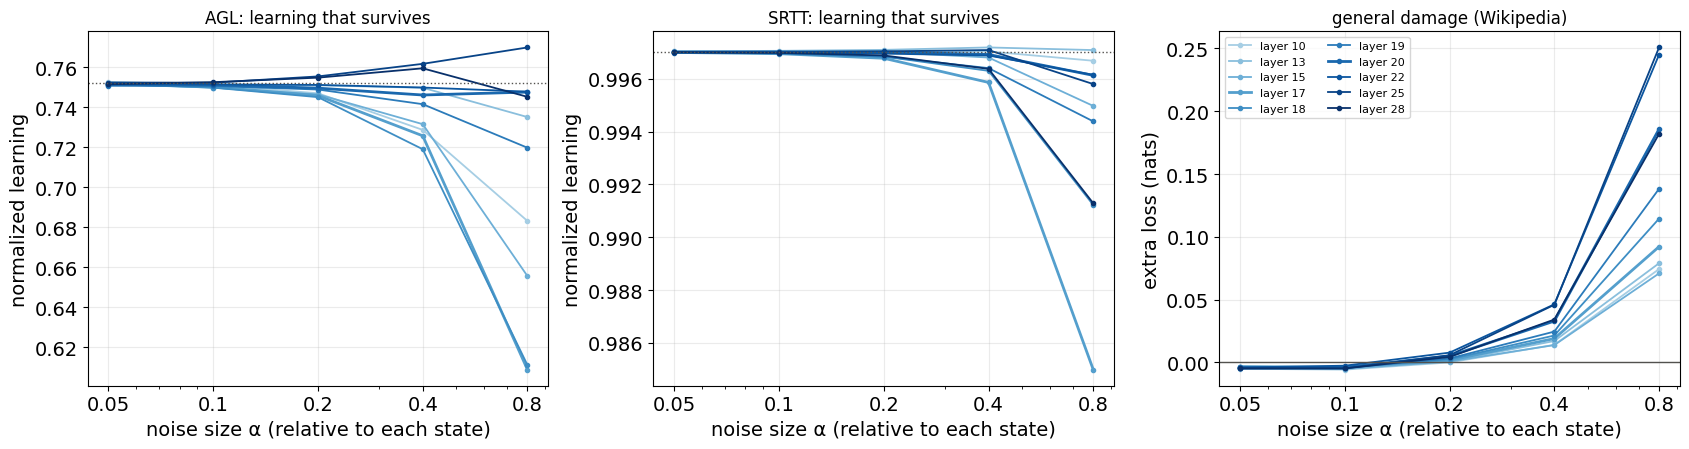

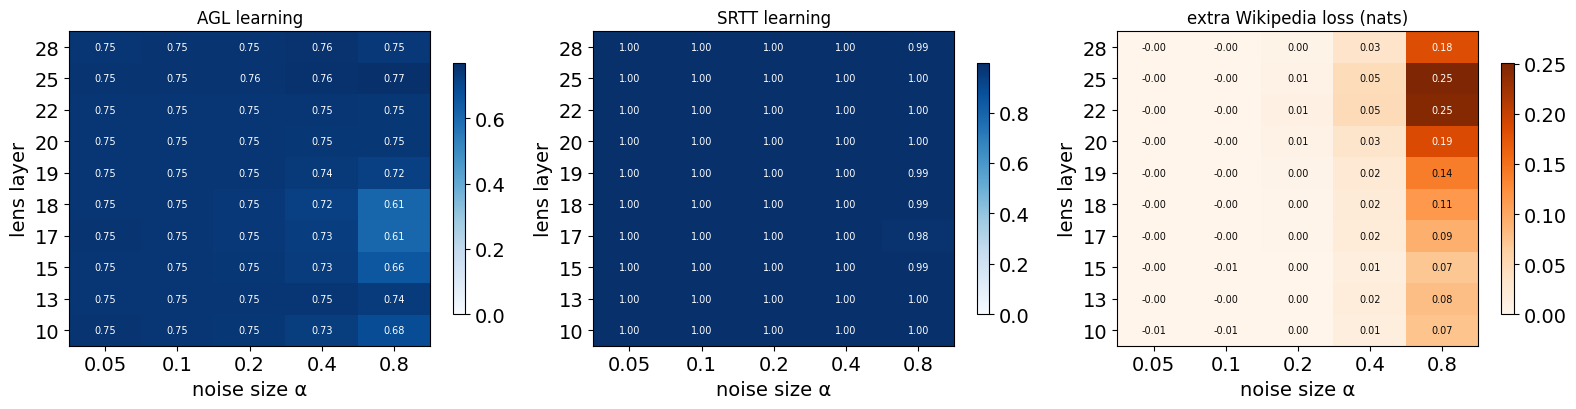

In [36]:
cmap = plt.get_cmap('Blues')
layer_colors = {L: cmap(0.35 + 0.65 * i / max(len(NOISE_LAYERS) - 1, 1)) for i, L in enumerate(NOISE_LAYERS)}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, metric in zip(axes, ("AGL", "SRTT", "Wiki")):
  for L in NOISE_LAYERS:
    if metric == "Wiki":
      values = [overview.loc[(L, a), "extra Wiki loss"] for a in NOISE_ALPHAS]
    else:
      values = [overview.loc[(L, a), f"{metric} learning"] for a in NOISE_ALPHAS]
    ax.plot(NOISE_ALPHAS, values, color=layer_colors[L], marker='o', markersize=3, linewidth=2 if L in COMPARE_LAYERS else 1.3,
            label=f"layer {L}")
  if metric != "Wiki":
    ax.axhline(learning(None, 0.0, metric)[0], color='#52514e', linestyle=':', linewidth=1, label="no noise")
    ax.set_ylabel("normalized learning")
    ax.set_title(f"{metric}: learning that survives")
  else:
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.set_ylabel("extra loss (nats)")
    ax.set_title("general damage (Wikipedia)")
  ax.set_xscale('log')
  ax.set_xticks(NOISE_ALPHAS)
  ax.set_xticklabels([f"{a:g}" for a in NOISE_ALPHAS])
  ax.set_xlabel("noise size α (relative to each state)")
  ax.grid(alpha=0.25)
axes[-1].legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (title, column, cmap_name, vmin, vmax) in zip(axes, (("AGL learning", "AGL learning", 'Blues', 0, None),
                                                             ("SRTT learning", "SRTT learning", 'Blues', 0, None),
                                                             ("extra Wikipedia loss (nats)", "extra Wiki loss", 'Oranges', 0, None))):
  grid = np.array([[overview.loc[(L, a), column] for a in NOISE_ALPHAS] for L in NOISE_LAYERS])
  im = ax.imshow(grid, origin='lower', aspect='auto', cmap=cmap_name, vmin=vmin, vmax=vmax)
  ax.set_xticks(range(len(NOISE_ALPHAS)))
  ax.set_xticklabels([f"{a:g}" for a in NOISE_ALPHAS])
  ax.set_yticks(range(len(NOISE_LAYERS)))
  ax.set_yticklabels(NOISE_LAYERS)
  ax.set_xlabel("noise size α")
  ax.set_ylabel("lens layer")
  ax.set_title(title)
  for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
      ax.text(j, i, f"{grid[i, j]:.2f}", ha='center', va='center', fontsize=7,
              color='white' if grid[i, j] > 0.6 * np.nanmax(grid) else '#0b0b0b')
  fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

### The key plot: learning vs. general damage
Each line is one layer; its points are the five noise sizes. The x-axis is general damage (extra Wikipedia loss), the
y-axis the learning that survives. Comparing layers **at the same general damage** is the fair comparison: a layer
whose line drops steeply on the left side (much learning lost for little damage) is specifically important for
in-context learning, not just generally important.

The bar plot reads each line at the same damage level (`DAMAGE_LEVEL`, interpolated between noise sizes): the learning
that survives when noise at that layer costs exactly that much on Wikipedia. Missing bars: noise at that layer never
caused that much damage within the tested sizes.

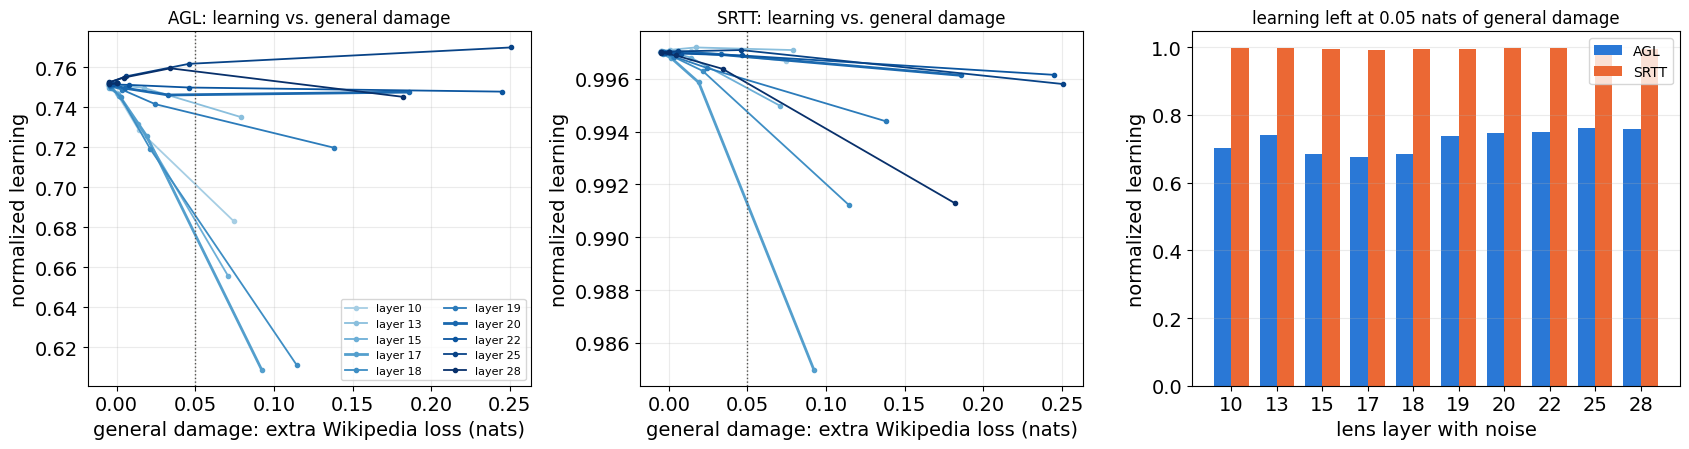

,AGL,SRTT
lens layer (learning at 0.05 nats damage),,
10,0.702,0.997
13,0.742,0.997
15,0.683,0.996
17,0.676,0.991
18,0.686,0.995
19,0.737,0.996
20,0.746,0.997
22,0.750,0.997
25,0.762,0.997


In [37]:
def learning_at_damage(L, grammar, level=DAMAGE_LEVEL):
  damage = [0.0] + [overview.loc[(L, a), "extra Wiki loss"] for a in NOISE_ALPHAS]
  values = [learning(None, 0.0, grammar)[0]] + [overview.loc[(L, a), f"{grammar} learning"] for a in NOISE_ALPHAS]
  damage = np.maximum.accumulate(damage)  # monotone for interpolation (noise only adds damage)
  return float(np.interp(level, damage, values)) if damage[-1] >= level else np.nan


fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, grammar in zip(axes[:2], ("AGL", "SRTT")):
  for L in NOISE_LAYERS:
    xs = [0.0] + [overview.loc[(L, a), "extra Wiki loss"] for a in NOISE_ALPHAS]
    ys = [learning(None, 0.0, grammar)[0]] + [overview.loc[(L, a), f"{grammar} learning"] for a in NOISE_ALPHAS]
    ax.plot(xs, ys, color=layer_colors[L], marker='o', markersize=3, linewidth=2 if L in COMPARE_LAYERS else 1.3, label=f"layer {L}")
  ax.axvline(DAMAGE_LEVEL, color='#52514e', linestyle=':', linewidth=1)
  ax.set_xlabel("general damage: extra Wikipedia loss (nats)")
  ax.set_ylabel("normalized learning")
  ax.set_title(f"{grammar}: learning vs. general damage")
  ax.grid(alpha=0.25)
axes[0].legend(fontsize=8, ncol=2)
width = 0.38
x = np.arange(len(NOISE_LAYERS))
for offset, grammar, color in ((-width / 2, "AGL", SERIES_COLORS["AGL"]), (width / 2, "SRTT", SERIES_COLORS["SRTT"])):
  axes[2].bar(x + offset, [learning_at_damage(L, grammar) for L in NOISE_LAYERS], width=width, color=color, label=grammar)
axes[2].set_xticks(x)
axes[2].set_xticklabels(NOISE_LAYERS)
axes[2].set_xlabel("lens layer with noise")
axes[2].set_ylabel("normalized learning")
axes[2].set_title(f"learning left at {DAMAGE_LEVEL:g} nats of general damage")
axes[2].legend()
axes[2].grid(alpha=0.25, axis='y')
fig.tight_layout()
plt.show()

display(pd.DataFrame({grammar: {L: learning_at_damage(L, grammar) for L in NOISE_LAYERS} for grammar in ("AGL", "SRTT")})
        .rename_axis(f"lens layer (learning at {DAMAGE_LEVEL:g} nats damage)").round(3))

### Before vs. after the jump: learning curves
The probability of the correct next word along the stream (final output, averaged over runs, smoothed over one
sequence length), without noise and with the same noise size at two layers: one just before the jump (layer 17) and
one just after it (layer 20). Dashed vertical lines: start and end of the grammar phase.

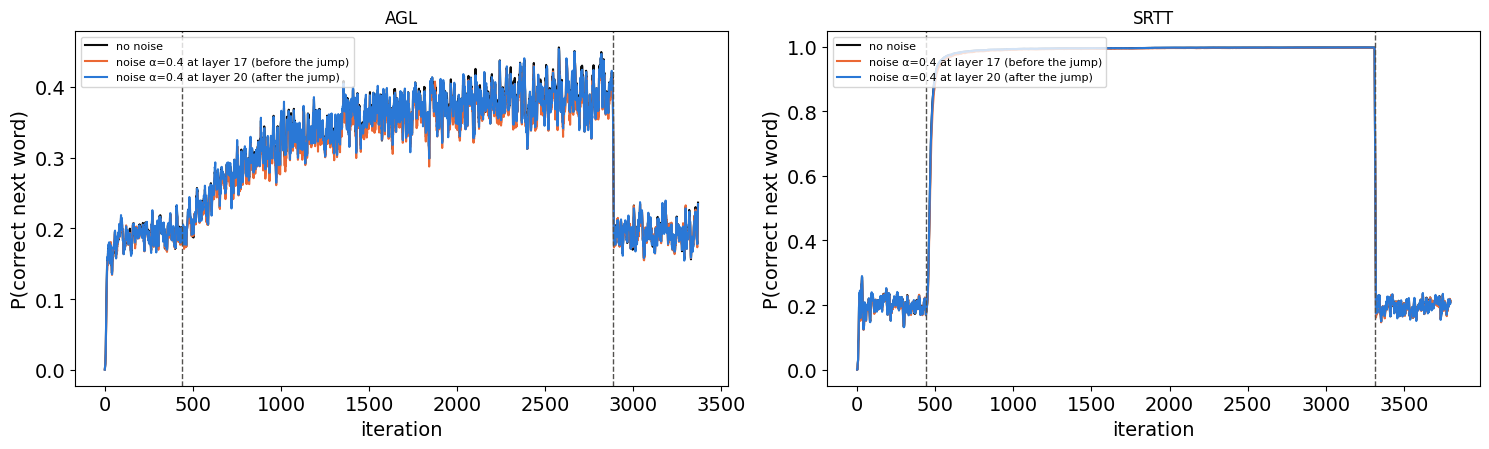

In [38]:
# fall back to the nearest tested settings if COMPARE_* is not in the lists above
compare_alpha = min(NOISE_ALPHAS, key=lambda a: abs(a - COMPARE_ALPHA))
before, after = (min(NOISE_LAYERS, key=lambda L: abs(L - target)) for target in COMPARE_LAYERS)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
styles = [((None, 0.0), "no noise", '#0b0b0b'),
          ((before, compare_alpha), f"noise α={compare_alpha:g} at layer {before} (before the jump)", '#eb6834'),
          ((after, compare_alpha), f"noise α={compare_alpha:g} at layer {after} (after the jump)", '#2a78d6')]
for ax, grammar, window in zip(axes, ("AGL", "SRTT"), (7, 9)):
  prompts = GRAMMAR_PROMPTS[grammar]
  for key, label, color in styles:
    curves = [lens_next_token_probs(r, renormalize=False)[-1:] for r in results[key][grammar]]
    aligned, (struct_start, struct_end) = align_runs(curves, prompts)
    ax.plot(uniform_filter1d(aligned[:, 0].mean(axis=0), size=window, mode='nearest'), color=color, linewidth=1.5, label=label)
  for x in (struct_start, struct_end):
    ax.axvline(x, color='#52514e', linestyle='--', linewidth=1)
  ax.set_title(grammar)
  ax.set_xlabel("iteration")
  ax.set_ylabel("P(correct next word)")
  ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()
plt.show()

## How to interpret the results

- **Learning breaks at a much lower damage level for layers just before the jump (≈ 15–18) than after it (≥ 20)** →
  the in-context computation happens at the jump, and it depends on a clean state there: the induction heads read the
  earlier words from it.
- **All layers look alike in the learning-vs-damage plot** → noise hurts in-context learning only as much as it hurts
  the model in general; there is no especially fragile stage.
- **Layers after the jump are also fragile** → the later layers keep doing essential work (they refine the
  prediction), consistent with the per-layer lens, where learning keeps growing up to the last layer.
- **SRTT survives noise better than AGL** → copying a fixed sequence is more robust than tracking a probabilistic
  rule, as in the head ablations.

Caveat: random noise in 4,096 dimensions mostly points in directions the model does not use, so the absolute α
values are not meaningful on their own; compare layers with each other, at the same damage.